# Exploración de datos

Estructura general:

1. Cargar **librerías** y fijar tema para las gráficas

2. Cargar **datos originales** y realizar inspección general: `head()`, `info()`, `describe()`

3. **Gráficar** grupos de variables 

4. Buscar valores tipo NaN y filtrar correspondientemente

    - Si un grupo considerable de NaN se concentra en una sola variables (columna), eliminarla

    - De lo contrario, eliminar las muestras (filas) que contengan al menos un NaN

5. Graficar variables de manera individual: Visualizar distribuciones e identificar outliers

    - Dataframe con los primeros 4 momentos de cada variable y la cantidad de outliers 

6. Cálculo de correlación lineal   

    - Generar distintos filtros

7. Exportar datasets para set utilizados en el código `model_launcher.ipynb`

---

- Para una descipción conceptual de las variables utilizadas a continuación, referirse a [GitHub](https://github.com/Lopez-504/ANN-PhotometricRedshiftEstimation/blob/main/Features-description.md)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(context='notebook', style='darkgrid', palette='colorblind')

# Cargar datos y realizar 1ra inspección

In [4]:
# Se retiró la pimera linea (#Table1) del archivo original 150k.csv  

df_raw = pd.read_csv('150k.csv')

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 68 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   z              150000 non-null  float64
 1   zErr           150000 non-null  float64
 2   dec            150000 non-null  float64
 3   decErr         150000 non-null  float64
 4   dered_g        150000 non-null  float64
 5   dered_i        150000 non-null  float64
 6   dered_r        150000 non-null  float64
 7   dered_u        150000 non-null  float64
 8   dered_z        150000 non-null  float64
 9   deVRad_g       150000 non-null  float64
 10  deVRad_i       150000 non-null  float64
 11  deVRad_r       150000 non-null  float64
 12  deVRad_z       150000 non-null  float64
 13  deVRadErr_g    150000 non-null  float64
 14  deVRadErr_i    150000 non-null  float64
 15  deVRadErr_r    150000 non-null  float64
 16  deVRadErr_z    150000 non-null  float64
 17  expPhi_g       150000 non-nul

Solo se tienen valores numéricos de tipo float64. Por tanto si existen valores inconsistentes (e.g., generados por errores en los instrumentos de medición) no están en forma de NaN sino que se denotan con un valor float64 específico.  

In [4]:
df_raw.head()

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
0,1.967009,0.001295,0.099945,0.004153,18.74923,18.55813,18.67467,18.87822,18.45218,0.091994,...,18.92338,19.15566,19.76303,18.72110,0.017365,0.015810,0.015986,0.029013,0.033841,57.405766
1,0.133383,0.000062,0.075584,0.009540,19.82256,18.39337,18.82100,21.98708,18.03142,0.833777,...,19.37808,19.95601,23.14468,18.83381,0.053584,0.083252,0.069951,0.343517,0.051267,57.488430
2,0.505413,0.000175,0.036211,0.036408,21.45808,18.62883,19.56389,21.53409,18.04682,0.939758,...,20.09372,21.19098,23.46836,19.39700,0.149051,0.025049,0.041548,0.401160,0.053212,57.590708
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599


Preliminarmente, se observa que no hay mucha variación entre los magnitudes medidas en diferentes bandas

In [5]:
df_raw.describe()

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,...,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.623556,0.009047,26.065982,0.046213,19.382333,18.686139,19.279233,20.907164,17.885864,2.320062,...,19.659901,20.267409,21.618330,18.814536,-0.850326,0.060864,0.082660,-0.561751,-0.360454,159.668317
std,0.680948,0.500482,27.296625,0.057168,100.208428,1.619159,1.727408,100.229178,68.449357,100.140394,...,1.191152,1.358463,100.226481,68.446516,99.993146,0.350136,1.680287,100.000166,68.306093,56.061613
min,0.000003,-6.000000,-8.731240,0.000581,-9999.000000,10.984870,11.544330,-9999.000000,-9999.000000,-9999.000000,...,14.250490,14.391180,-9999.000000,-9999.000000,-9999.000000,0.007652,0.007005,-9999.000000,-9999.000000,5.715961
25%,0.165326,0.000030,-0.269621,0.011711,18.536315,17.208308,17.613557,20.046878,16.935880,0.456565,...,18.736677,19.125528,21.216950,18.434185,0.024549,0.020636,0.020218,0.088724,0.034567,127.488092
50%,0.475981,0.000104,14.532019,0.030656,20.889490,19.126615,19.827730,21.998690,18.733645,1.770002,...,19.957015,20.544065,22.774890,19.549170,0.060388,0.033562,0.038637,0.329134,0.073749,159.537029
75%,0.634242,0.000187,53.410681,0.062214,21.910835,19.813852,20.640403,23.568597,19.429057,3.753671,...,20.536603,21.376780,24.018160,20.074288,0.148888,0.050262,0.069605,0.683660,0.115950,199.928563
max,5.976685,68.149880,68.739531,3.907853,29.960940,30.005690,31.137200,29.817460,28.150440,29.688530,...,24.362560,24.806330,26.956760,24.124420,290.553500,45.547210,621.494400,420.356800,35.254630,348.902530


- Se observan valores `-9999` en multiples columnas, inconsistentes con las magnitudes que representantan, por lo cual se asume que estos son valores faltantes.
- Se procede a contar la cantidad de valores `-9999` y cuántas filas presentan al menos una columna con este valor

In [6]:
# Total  
print((df_raw==-9999).sum(numeric_only=False).sum())       # 345 '-9999' NaN

# Al menos una por cada fila
(df_raw==-9999).any(axis=1).sum()               

345


np.int64(17)

- Solo 17 de 150000 muestras serán descartadas

In [5]:
# Quitar filas con al menos un NaN
df_1 = df_raw[~(df_raw==-9999).any(axis=1)].copy()
print((df_1==-9999).sum(numeric_only=False).sum())                  # Verificar 
df_1

0


,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
0,1.967009,0.001295,0.099945,0.004153,18.74923,18.55813,18.67467,18.87822,18.45218,0.091994,...,18.92338,19.15566,19.76303,18.72110,0.017365,0.015810,0.015986,0.029013,0.033841,57.405766
1,0.133383,0.000062,0.075584,0.009540,19.82256,18.39337,18.82100,21.98708,18.03142,0.833777,...,19.37808,19.95601,23.14468,18.83381,0.053584,0.083252,0.069951,0.343517,0.051267,57.488430
2,0.505413,0.000175,0.036211,0.036408,21.45808,18.62883,19.56389,21.53409,18.04682,0.939758,...,20.09372,21.19098,23.46836,19.39700,0.149051,0.025049,0.041548,0.401160,0.053212,57.590708
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


Explorar variables

In [12]:
# Totalidad de variables disponibles
df_1.columns

Index(['z', 'zErr', 'dec', 'decErr', 'dered_g', 'dered_i', 'dered_r',
       'dered_u', 'dered_z', 'deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z',
       'deVRadErr_g', 'deVRadErr_i', 'deVRadErr_r', 'deVRadErr_z', 'expPhi_g',
       'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z', 'expRad_g', 'expRad_i',
       'expRad_r', 'expRad_z', 'expRadErr_g', 'expRadErr_i', 'expRadErr_r',
       'expRadErr_z', 'extinction_g', 'extinction_i', 'extinction_r',
       'extinction_u', 'extinction_z', 'fiberMag_g', 'fiberMag_i',
       'fiberMag_r', 'fiberMag_u', 'fiberMag_z', 'fiberMagErr_g',
       'fiberMagErr_i', 'fiberMagErr_r', 'fiberMagErr_u', 'fiberMagErr_z',
       'modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z',
       'modelMagErr_g', 'modelMagErr_i', 'modelMagErr_r', 'modelMagErr_u',
       'modelMagErr_z', 'petroRad_r', 'petroRadErr_r', 'psfMag_g', 'psfMag_i',
       'psfMag_r', 'psfMag_u', 'psfMag_z', 'psfMagErr_g', 'psfMagErr_i',
       'psfMagErr_r', 'psfMagErr_u', 

Explorar cuantas bandas se tienen por cada magnitud

In [20]:
c=0                         # contador para verificar que se evaluaron las 68 variables 
for i in df_1.columns:
    if i[:5]=='dered':
        print(i)      
        c+=1

    if i[:5]=='fiber':
        print(i)   
        c+=1

dered_g
dered_i
dered_r
dered_u
dered_z
fiberMag_g
fiberMag_i
fiberMag_r
fiberMag_u
fiberMag_z
fiberMagErr_g
fiberMagErr_i
fiberMagErr_r
fiberMagErr_u
fiberMagErr_z


Bandas **giruz** para `dered`, `fiberMag` y `fiberMagErr`

In [21]:
for i in df_raw.columns:
    if i[:3]=='deV':
        print(i)
        c+=1

    if i[:3]=='exp':
        print(i)
        c+=1           

deVRad_g
deVRad_i
deVRad_r
deVRad_z
deVRadErr_g
deVRadErr_i
deVRadErr_r
deVRadErr_z
expPhi_g
expPhi_i
expPhi_r
expPhi_u
expPhi_z
expRad_g
expRad_i
expRad_r
expRad_z
expRadErr_g
expRadErr_i
expRadErr_r
expRadErr_z


Bandas **giruz** para `expPhi`, y solo **girz** para `deVRad`, `deVRadErr`, `expRad` y `expRadErr`

In [22]:
for i in df_raw.columns:
    if i[:3]=='ext':
        print(i)
        c+=1

    if i[:5]=='model':
        print(i)
        c+=1  

extinction_g
extinction_i
extinction_r
extinction_u
extinction_z
modelMag_g
modelMag_i
modelMag_r
modelMag_u
modelMag_z
modelMagErr_g
modelMagErr_i
modelMagErr_r
modelMagErr_u
modelMagErr_z


Bandas **giruz** para `extinction`, `modelMag` y `modelMagErr`

In [23]:
for i in df_raw.columns:
    if i[:3]=='psf':
        print(i)
        c+=1

    if i[:5]=='petro':
        print(i)
        c+=1  

petroRad_r
petroRadErr_r
psfMag_g
psfMag_i
psfMag_r
psfMag_u
psfMag_z
psfMagErr_g
psfMagErr_i
psfMagErr_r
psfMagErr_u
psfMagErr_z


Bandas **giruz** para `psfMag` y `psfMagErr`, y solo **r** para `petroRad` y `petroRadErr`  

In [24]:
c

63

Se verifica la evaluación de todas las variables, 63 + 3 posición + 2 redshift

- Posición: `ra`, `dec`, `decErr`
- Redshift: `z`, `zErr`

A continuación se separan las variables en 3 categorías cualitativas: 

1. Positional and Redshift
2. Magnitude and Flux Measurements
3. Morphological and Shape

In [111]:
# Definir categorías
categories = {
    'Positional and Redshift': ['z', 'zErr', 'dec', 'decErr', 'ra'],
    'Magnitude and Flux Measurements': ['dered_g', 'dered_i', 'dered_r', 'dered_u', 'dered_z', 'extinction_g', 'extinction_i', 'extinction_r', 'extinction_u', 'extinction_z', 'fiberMag_g', 'fiberMag_i', 'fiberMag_r', 'fiberMag_u', 'fiberMag_z', 'fiberMagErr_g', 'fiberMagErr_i', 'fiberMagErr_r', 'fiberMagErr_u', 'fiberMagErr_z', 'modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z', 'modelMagErr_g', 'modelMagErr_i', 'modelMagErr_r', 'modelMagErr_u', 'modelMagErr_z', 'psfMag_g', 'psfMag_i', 'psfMag_r', 'psfMag_u', 'psfMag_z', 'psfMagErr_g', 'psfMagErr_i', 'psfMagErr_r', 'psfMagErr_u', 'psfMagErr_z'],
    'Morphological and Shape': ['deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z', 'deVRadErr_g', 'deVRadErr_i', 'deVRadErr_r', 'deVRadErr_z', 'expRad_g', 'expRad_i', 'expRad_r', 'expRad_z', 'expRadErr_g', 'expRadErr_i', 'expRadErr_r', 'expRadErr_z', 'petroRad_r', 'petroRadErr_r','expPhi_g', 'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z']
}

# Dataframe cualitativo
df_q = df_1.copy()

# Creación de MultiIndex
multi_index_tuples = []
for category, columns in categories.items():
    for col in columns:
        if col in df_q.columns:
            multi_index_tuples.append((category, col))

new_columns = pd.MultiIndex.from_tuples(multi_index_tuples, names=['Category', 'Variable'])
df_q.columns = new_columns

In [112]:
df_q

Category Positional and Redshift                                           \
Variable                       z      zErr        dec    decErr        ra   
0                       1.967009  0.001295   0.099945  0.004153  18.74923   
1                       0.133383  0.000062   0.075584  0.009540  19.82256   
2                       0.505413  0.000175   0.036211  0.036408  21.45808   
3                       1.248642  0.000341   0.971539  0.012089  20.41834   
4                       0.066696  0.000006   1.047021  0.015802  19.00809   
...                          ...       ...        ...       ...       ...   
149995                  0.523190  0.000102  56.332271  0.039700  21.26369   
149996                  0.508194  0.000221  61.501827  0.044107  22.25257   
149997                  0.234232  0.000044  61.015388  0.012894  18.94200   
149998                  0.352076  0.000068  60.126007  0.015690  20.67480   
149999                  0.159817  0.000034  58.108272  0.008019  18.33011   

Category Magnitude and Flux Measurements                                \
Variable                         dered_g   dered_i   dered_r   dered_u   
0                               18.55813  18.67467  18.87822  18.45218   
1                               18.39337  18.82100  21.98708  18.03142   
2                               18.62883  19.56389  21.53409  18.04682   
3                               20.08604  19.99310  20.21941  20.27955   
4                               18.25147  18.56176  19.90209  18.13738   
...                                  ...       ...       ...       ...   
149995                          18.45656  19.38538  23.55142  17.99068   
149996                          19.64563  20.59183  22.66739  19.18695   
149997                          17.13919  17.64632  20.86497  16.80165   
149998                          18.40559  19.04279  22.63412  17.99781   
149999                          16.76323  17.19137  20.31705  16.42603   

Category            ... Morphological and Shape                          \
Variable   dered_z  ...             expRadErr_i expRadErr_r expRadErr_z   
0         0.091994  ...                18.92338    19.15566    19.76303   
1         0.833777  ...                19.37808    19.95601    23.14468   
2         0.939758  ...                20.09372    21.19098    23.46836   
3         0.230714  ...                20.20711    20.18484    20.56856   
4         1.461907  ...                19.12809    19.55080    21.05799   
...            ...  ...                     ...         ...         ...   
149995    2.787953  ...                19.47815    20.38832    24.53234   
149996    3.709756  ...                20.54820    21.43578    23.25575   
149997    4.772612  ...                19.02218    19.42988    22.61482   
149998    1.564977  ...                19.36206    19.97786    23.25273   
149999    2.749339  ...                18.26872    18.54049    21.60494   

Category                                                                   \
Variable petroRad_r petroRadErr_r  expPhi_g  expPhi_i  expPhi_r  expPhi_u   
0          18.72110      0.017365  0.015810  0.015986  0.029013  0.033841   
1          18.83381      0.053584  0.083252  0.069951  0.343517  0.051267   
2          19.39700      0.149051  0.025049  0.041548  0.401160  0.053212   
3          20.31880      0.037061  0.045533  0.028918  0.050030  0.120847   
4          18.91005      0.019690  0.023346  0.018100  0.068637  0.039914   
...             ...           ...       ...       ...       ...       ...   
149995     19.02971      0.108178  0.022276  0.038616  0.875940  0.045896   
149996     20.00042      0.156003  0.046724  0.055938  0.410539  0.105663   
149997     18.63499      0.027229  0.018064  0.016232  0.230208  0.036420   
149998     18.96493      0.050867  0.023696  0.025761  0.385661  0.046441   
149999     17.81150      0.020006  0.018885  0.016887  0.120106  0.023813   

Category              
Variable    expPhi_z  
0          

In [ ]:
# Exportar dataframe en formato pickle para las siguientes secciones
df_q.to_pickle('150k_quali-multiindex.pkl')

# Distribución de variables por categoría

In [2]:
df_q = pd.read_pickle('150k_quali-multiindex.pkl')

---

Categoría 1: **Positional and Redshift**

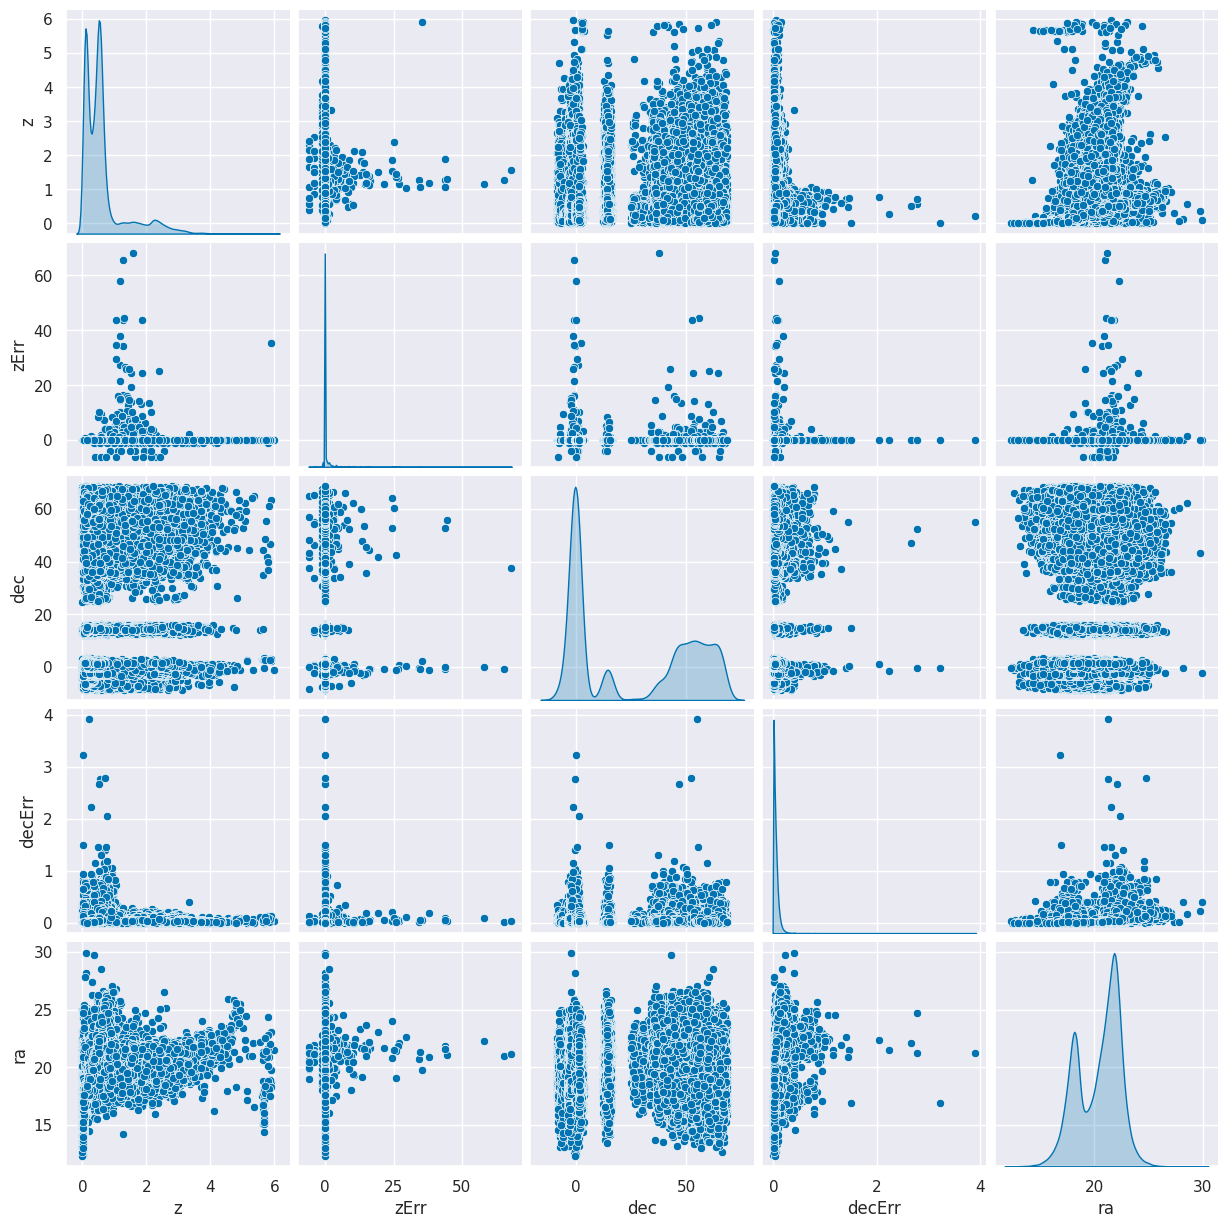

In [29]:
sns.pairplot(df_q['Positional and Redshift'], diag_kind='kde')

**Observaciones**:

- Se observan concentraciones muy altas de valore cercanos a cero y outliers ubicados al extremo derecho tanto en `decErr` como en `zErr` 
- Se visualiza una distribución trimodal en `dec` y bimodal en `ra`, indicando un máximo de 6 marcadas zonas en el cielo 
- Se visualiza una distribución bimodal en `z` concentrada en valores entre 0 y 1
- Se observa una gran cantidad de valores en `zErr` ubicados exactamente en cero, pero esto podría ser un defecto del rango en el que se está visualizando 

---

Categoría 2: **Magnitude and Flux Measurements**

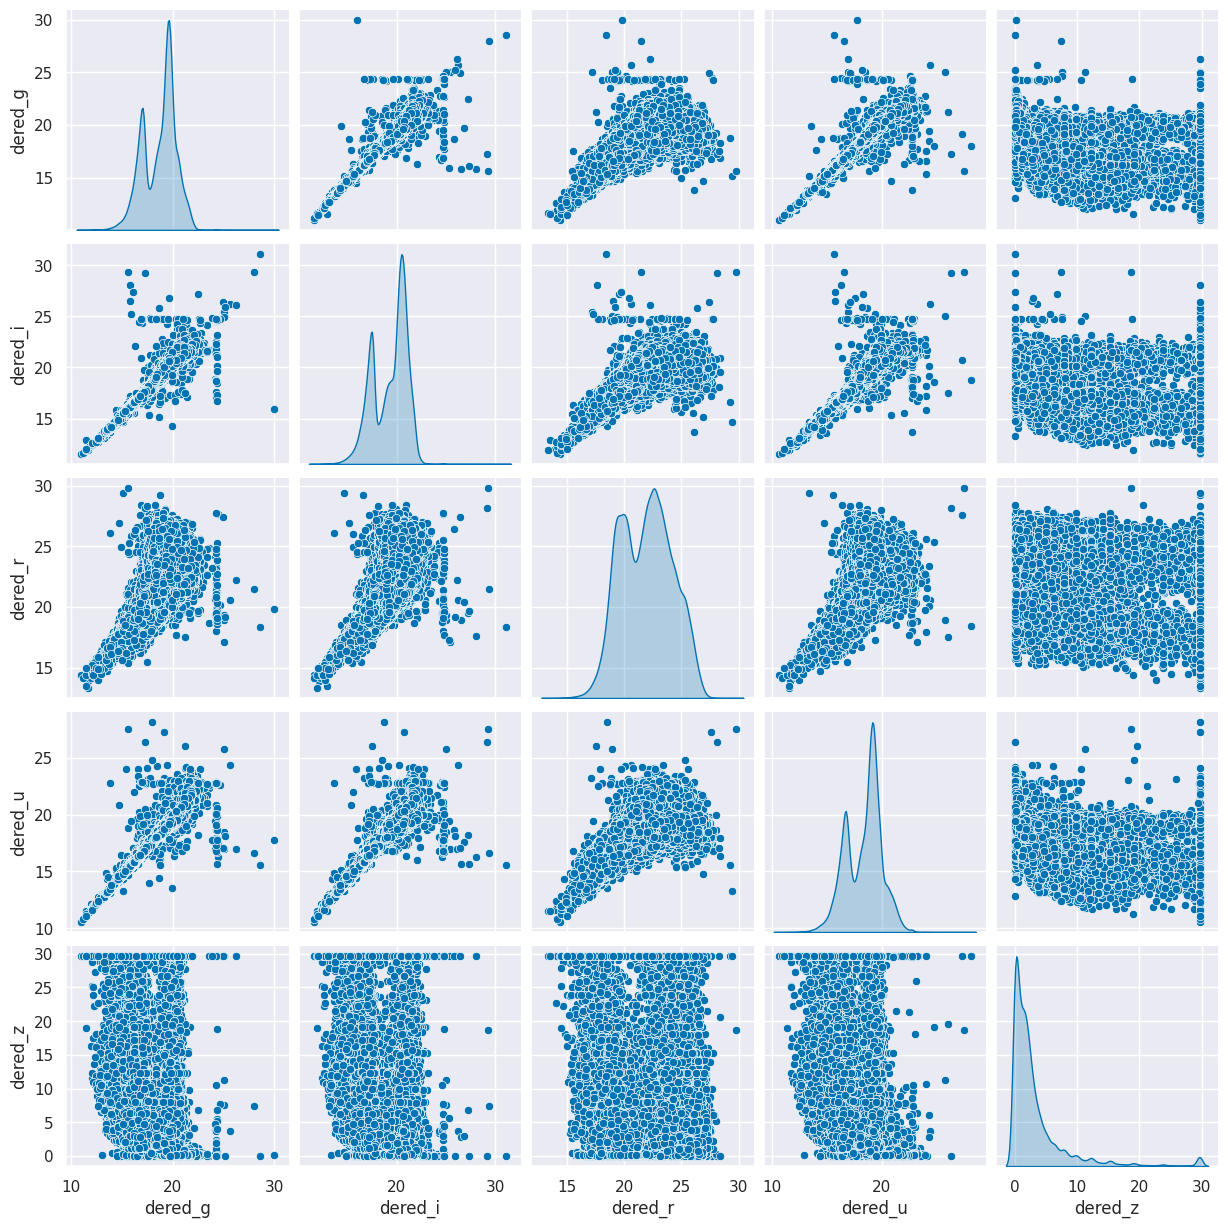

In [34]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, :5], diag_kind='kde')

- Se observan distribuciones similares y correlaciones bastante marcadas entre todas las bandas excepto **z**, en la cual la moda parece estar cercana a $0$, y un a moda menor cercana a $30$
- Dada la forma similar a una gaussina de esta moda menor, se intuye que podrían corresponder a valores artificiales 

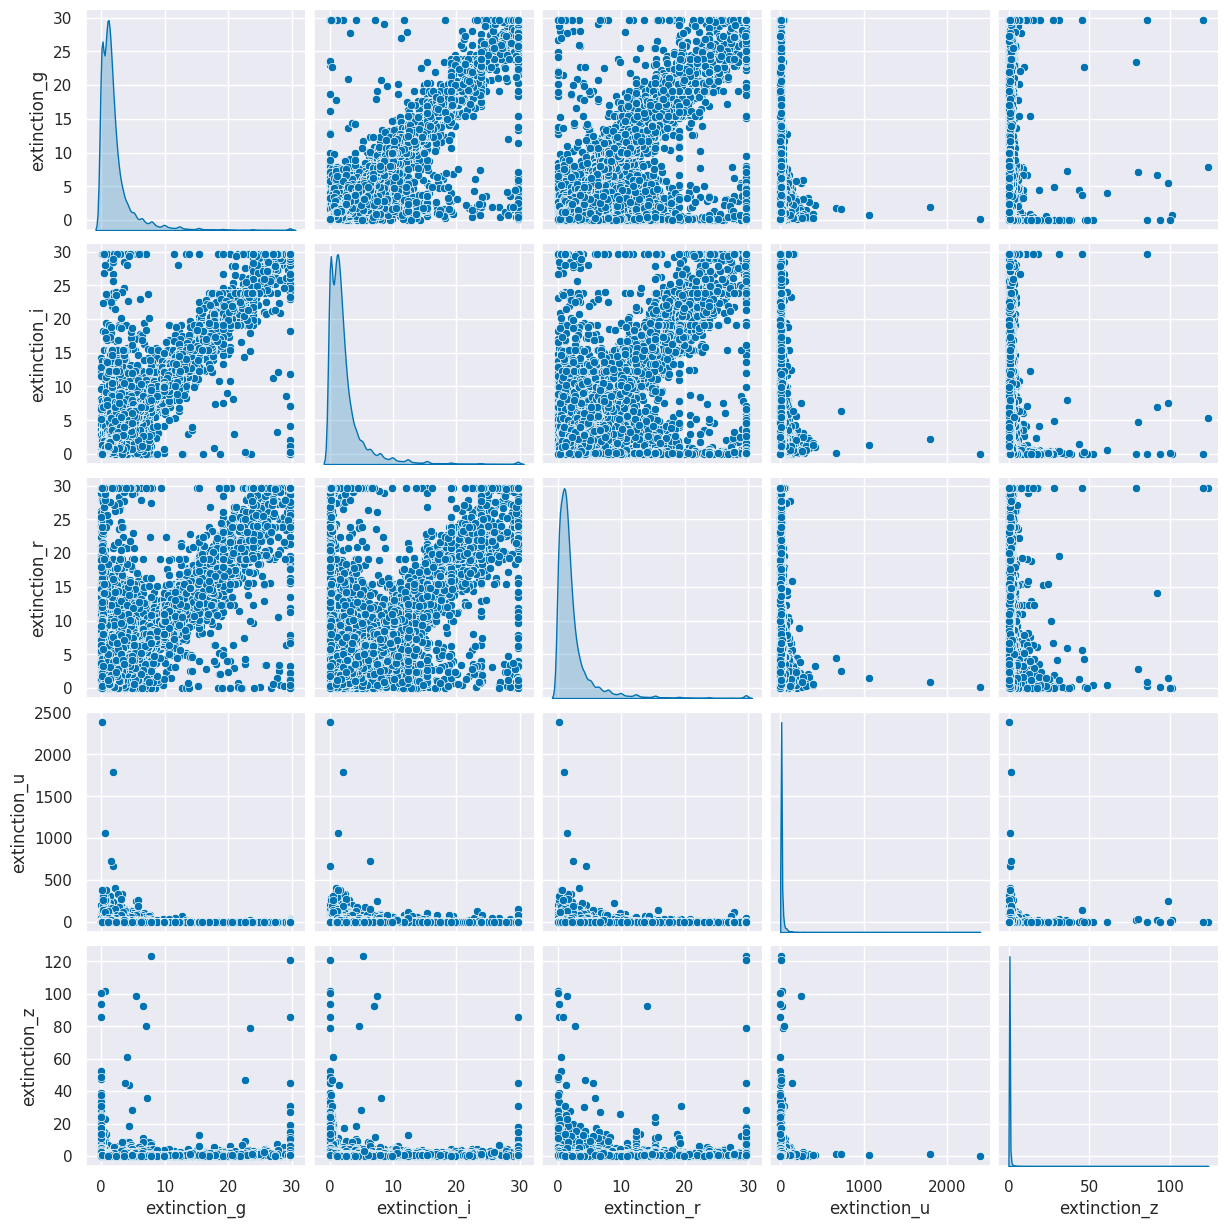

In [40]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 5:10], diag_kind='kde')

- En todas las variables se observa una moda muy marcada y cercana a $0$
- Se observa que unos pocos outliers de gran valor están ocultando la variabilidad en las bandas **u** y **z**
- En las demás bandas se observa una correlación positiva, pero a su vez muchos valores cercanos al máximo (i.e. $30$)

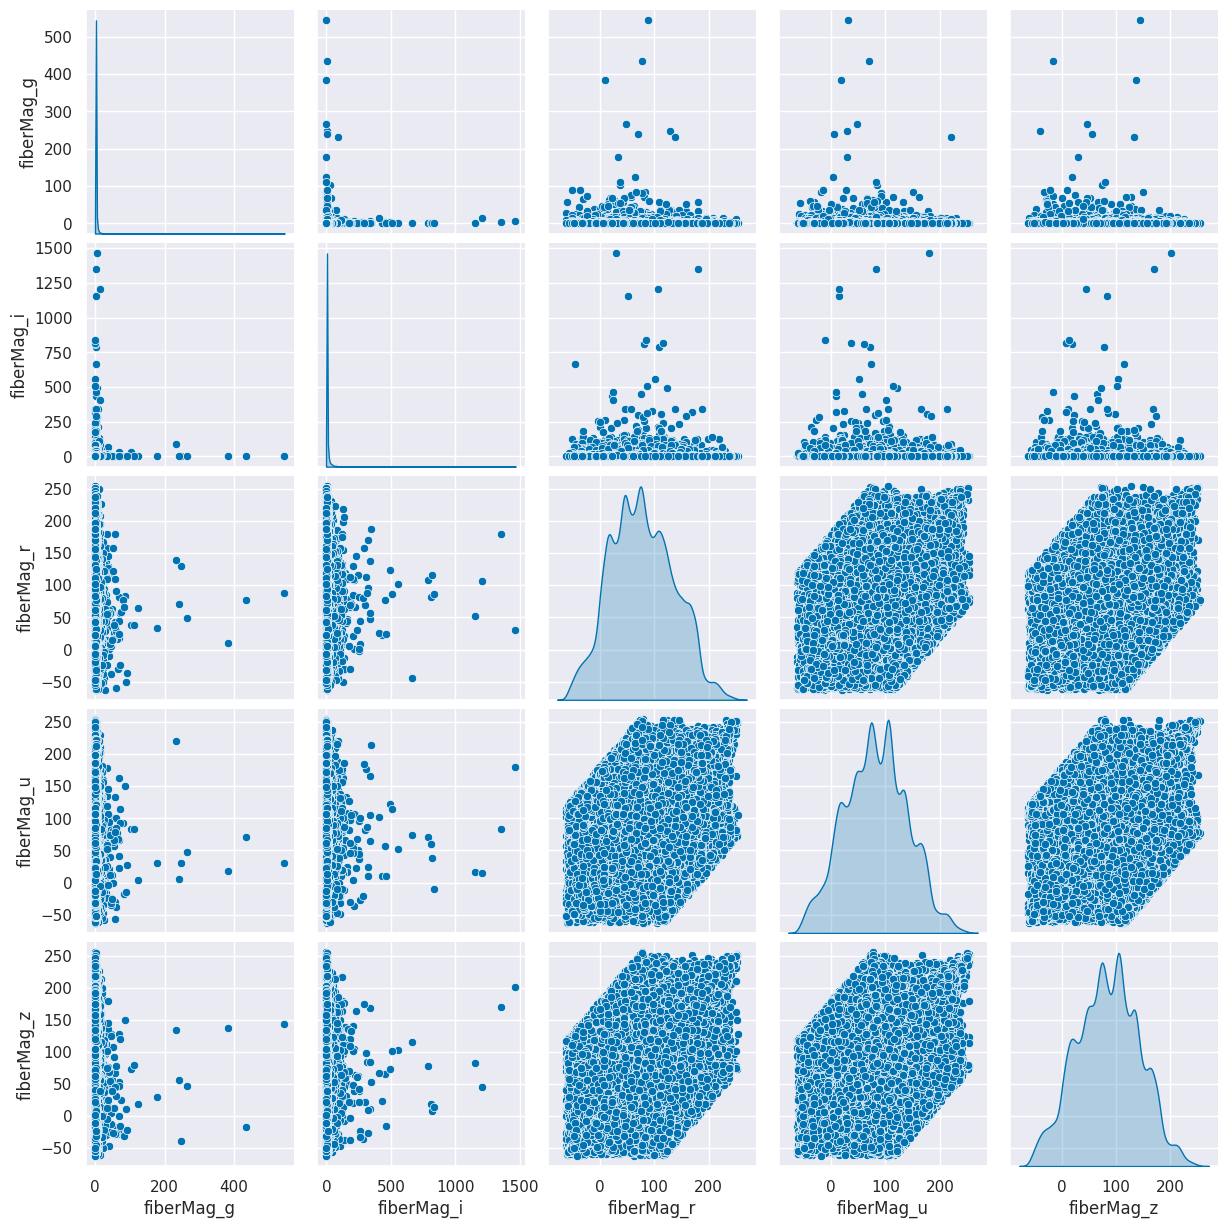

In [43]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 10:15], diag_kind='kde')

- En las bandas **ruz** se observan distribuciones cercanas a una normal
- En las bandas **gi** se observa una constribución de outliers que oculta la distribución de la mayoría de los valores cercanos a $0$

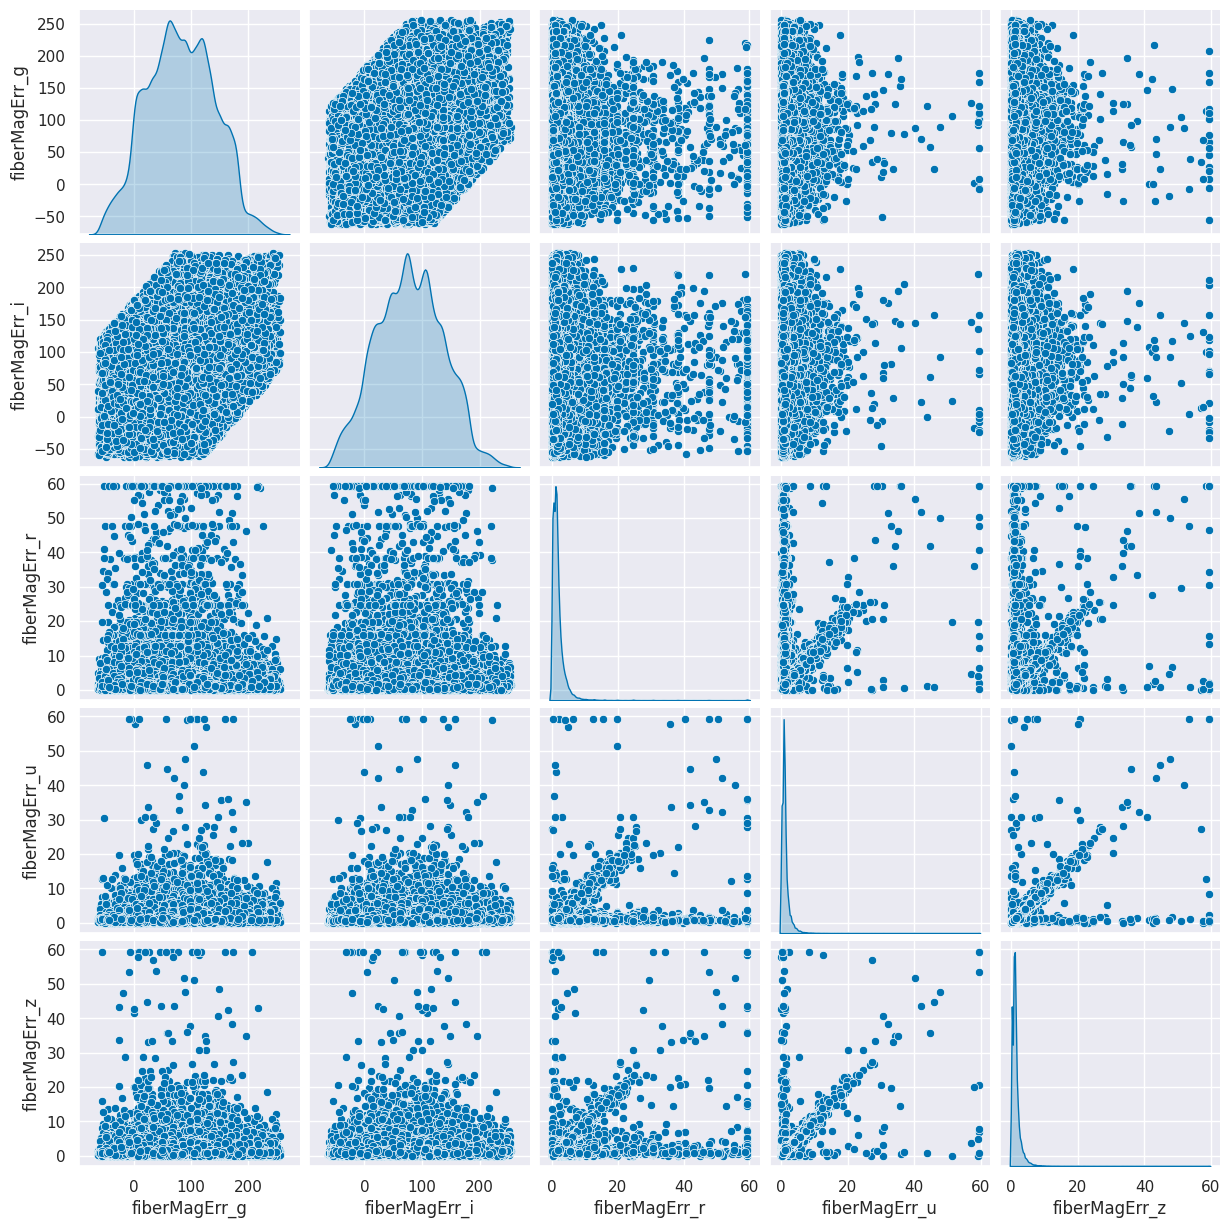

In [45]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 15:20], diag_kind='kde')

- Se observa una situación contraria a las variables `fiberMag`. En este caso, las bandas **gi** distribuyen de manera normal y son las bandas **ruz** las que presentan una gran cantidad de outliers.
- Notar que no se tienen valores negativos para las bandas **ruz**

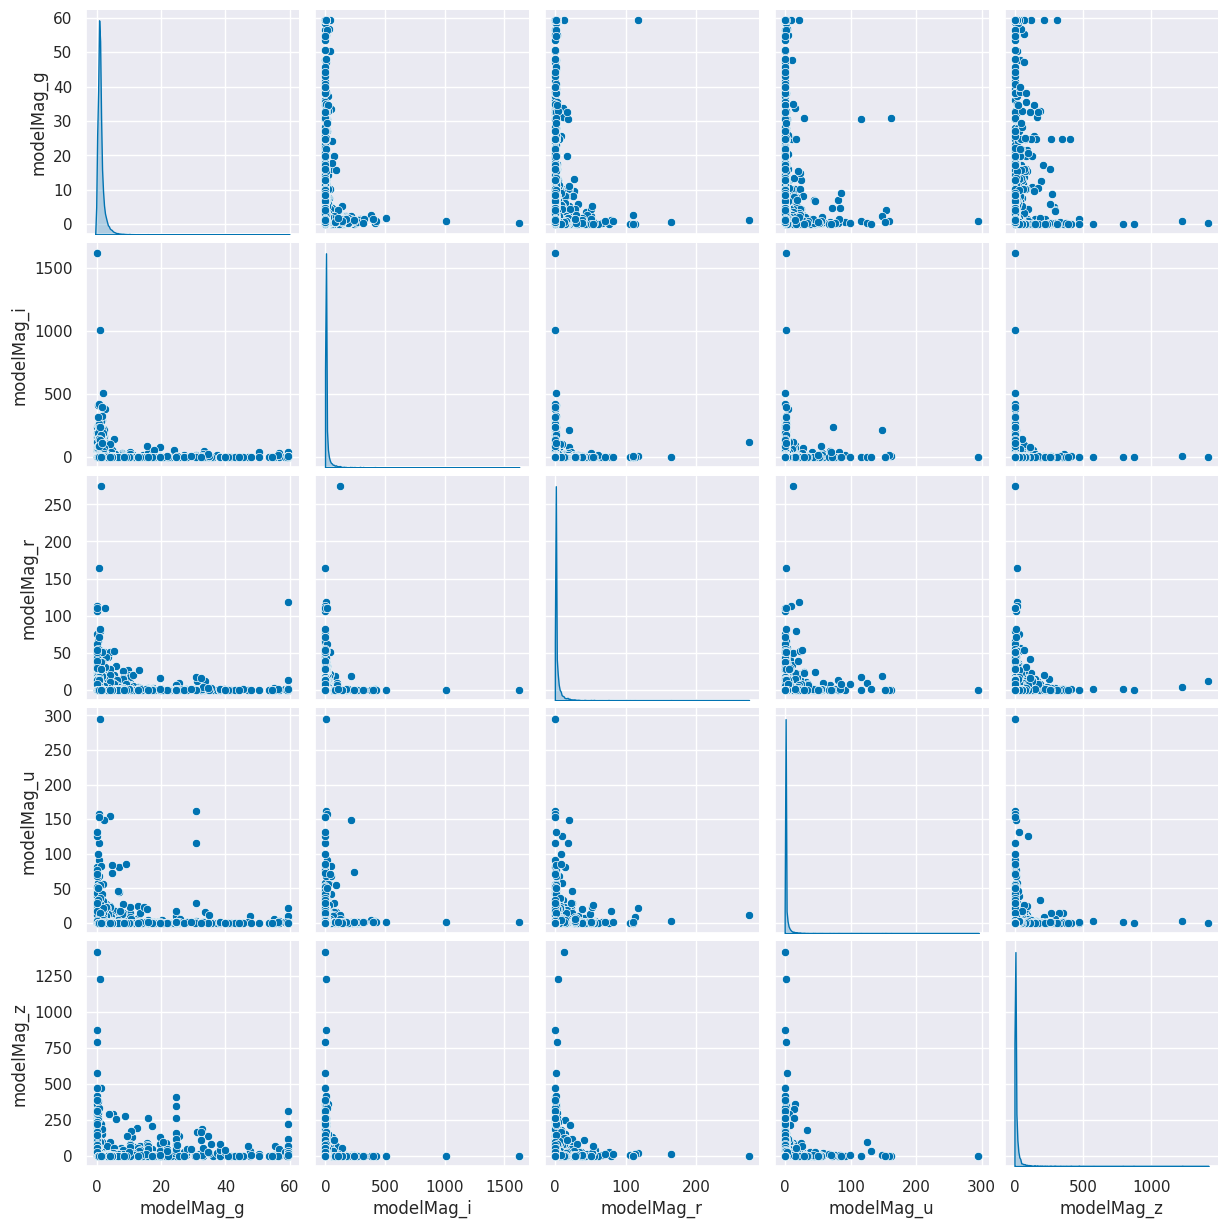

In [47]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 20:25], diag_kind='kde')

- Se observan pocos outliers pero que se ubican en valores muy altos comparados con la moda de la distribución

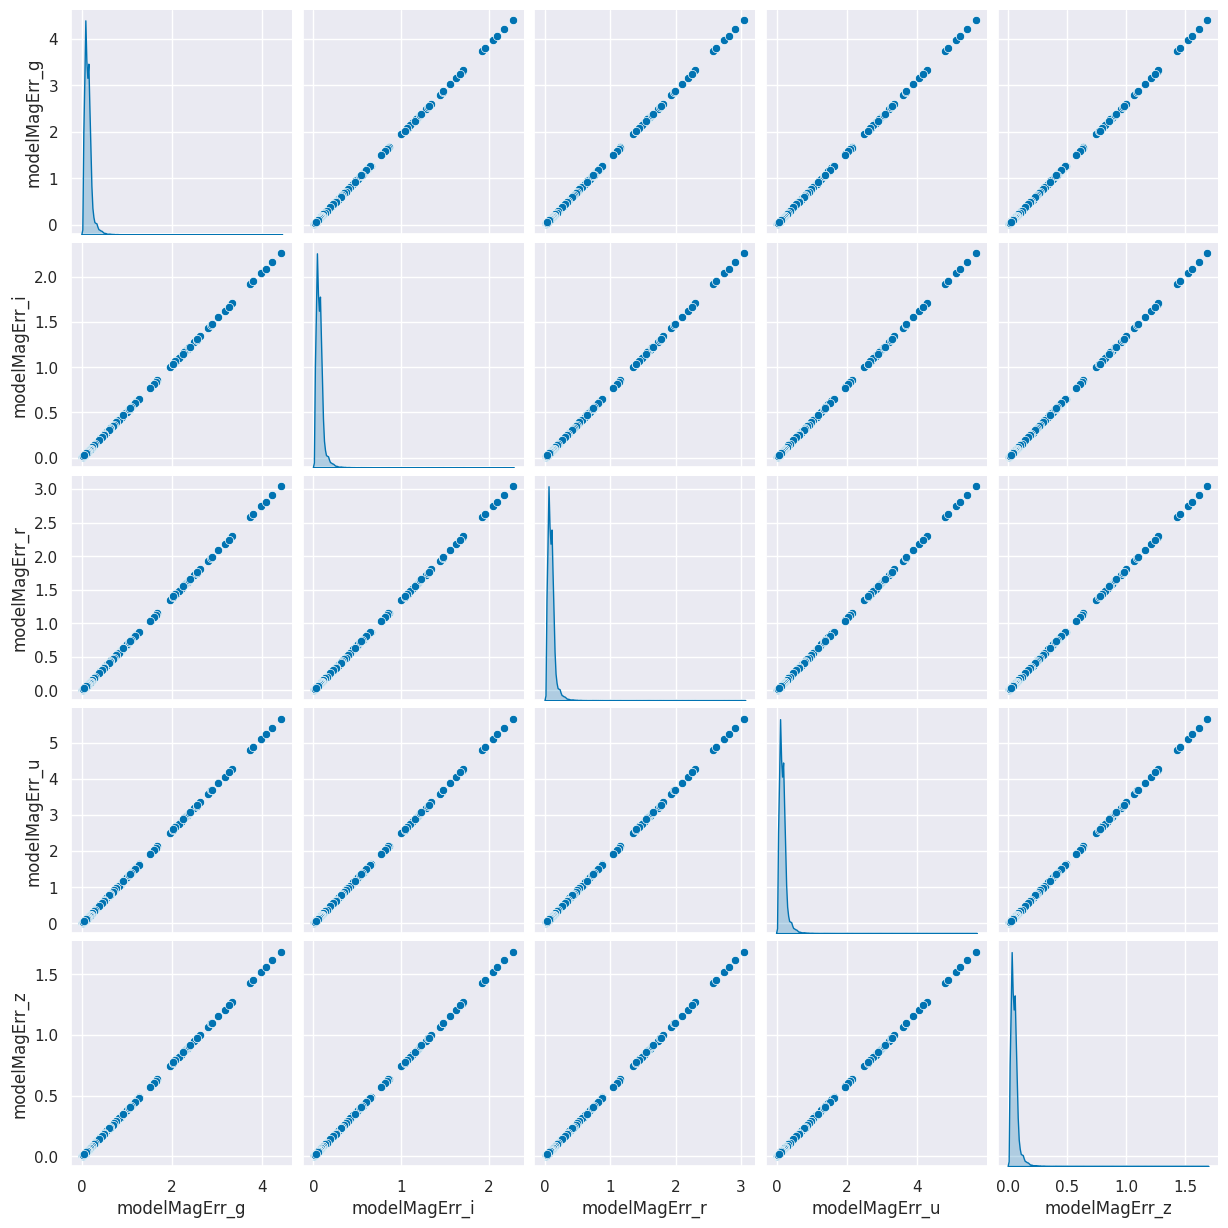

In [48]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 25:30], diag_kind='kde')


- Se observa, al igual que en el caso anterior, que unos pocos outliers ocultan la distribución de los valores que se concentran en zonas cercanas a $0$
- A pesar de las pequeñas variaciones en los rangos de estas bandas, se observan correlaciones casi exactamentes unitarias
- Incluir estas 5 variables en una red neuronal resultaría en un entrenamiento ineficiente a causa de la redundancia que este conjunto presenta 

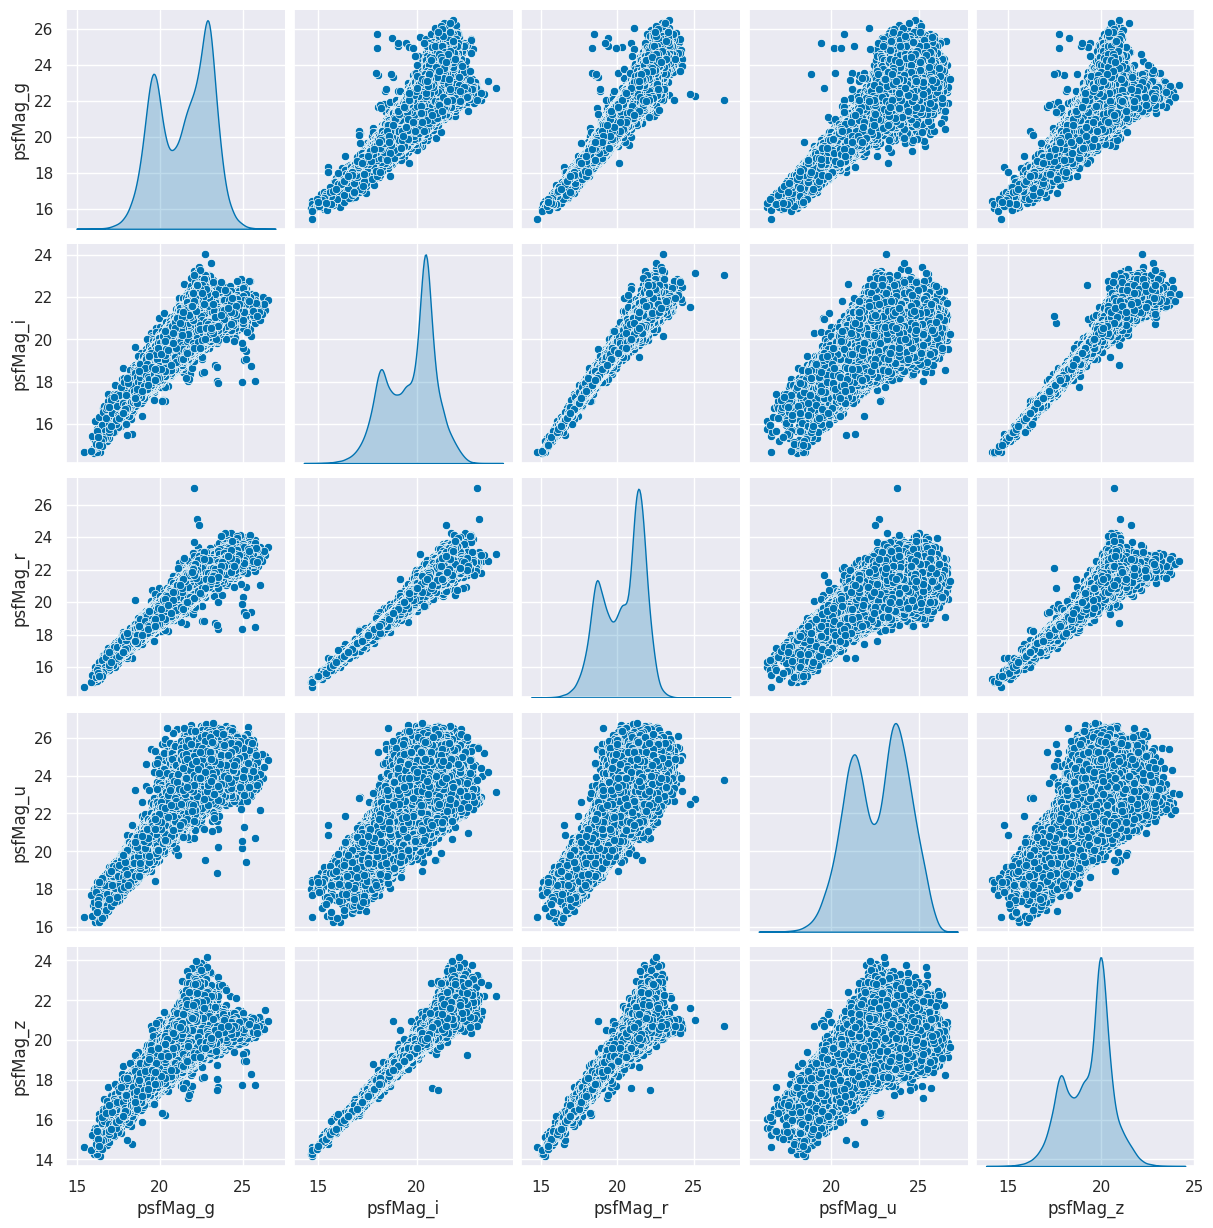

In [52]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 30:35], diag_kind='kde')

- Se observan distribuciones bimodales en todas las bandas, correlaciones positivas cercanas a $1$ y poca influencia de outliers 

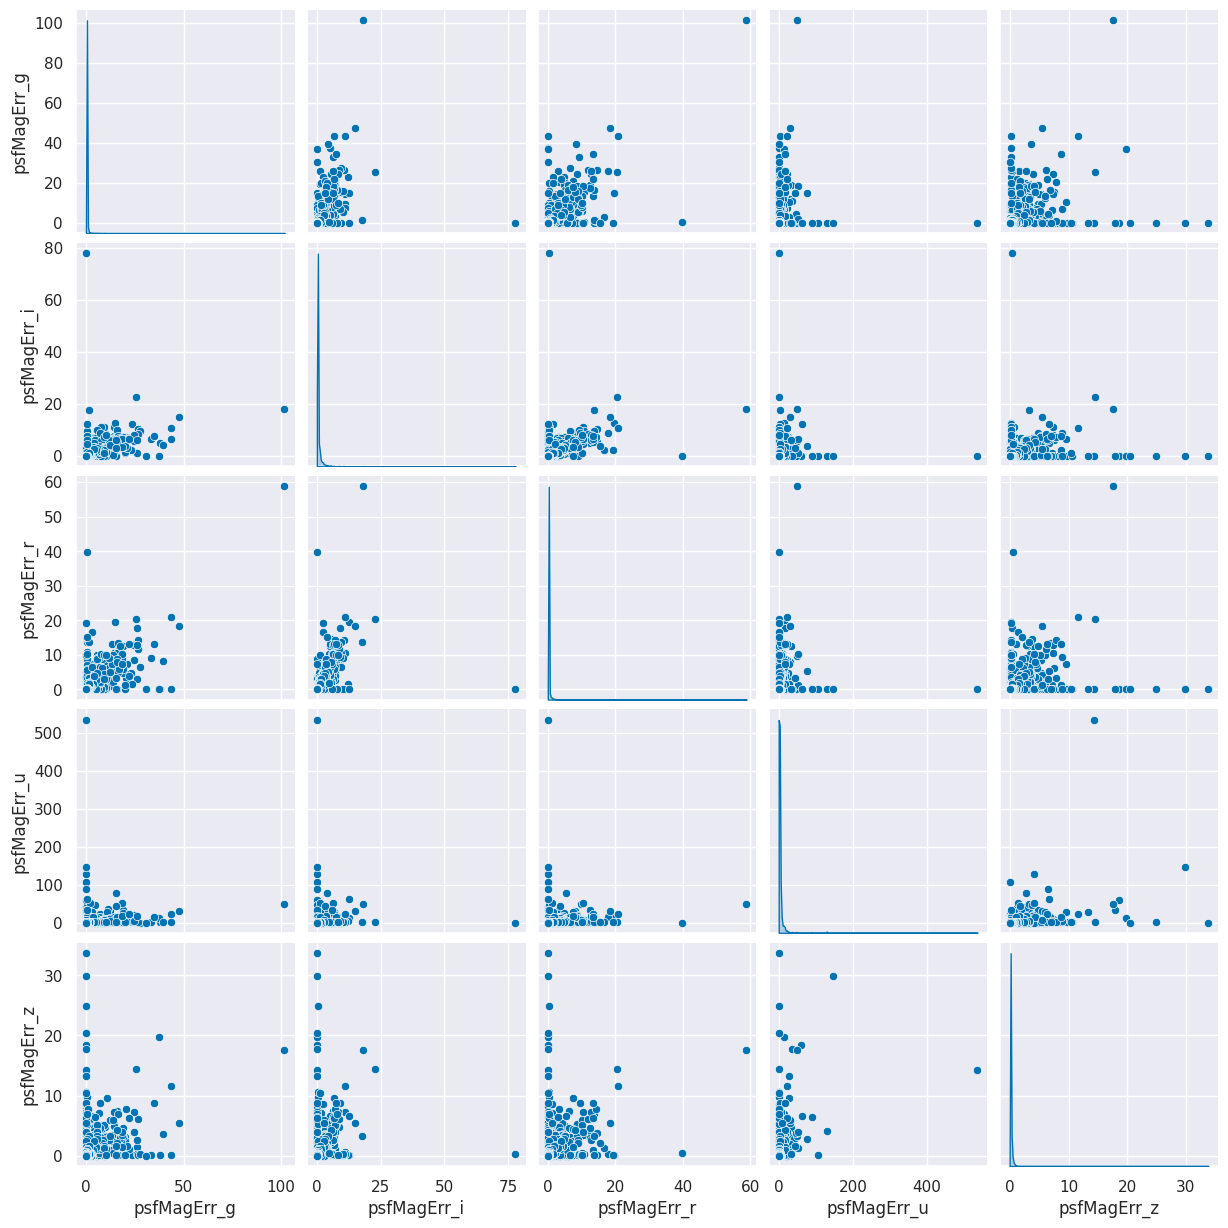

In [53]:
sns.pairplot(df_q['Magnitude and Flux Measurements'].iloc[:, 35:40], diag_kind='kde')

- La presencia de outliers impide visualizar la distribución en todas las bandas, pero nuevamente se observa que los errores se ubican en zonas muy cercanas a $0$

---

Categoría 3: Morphological and Shape

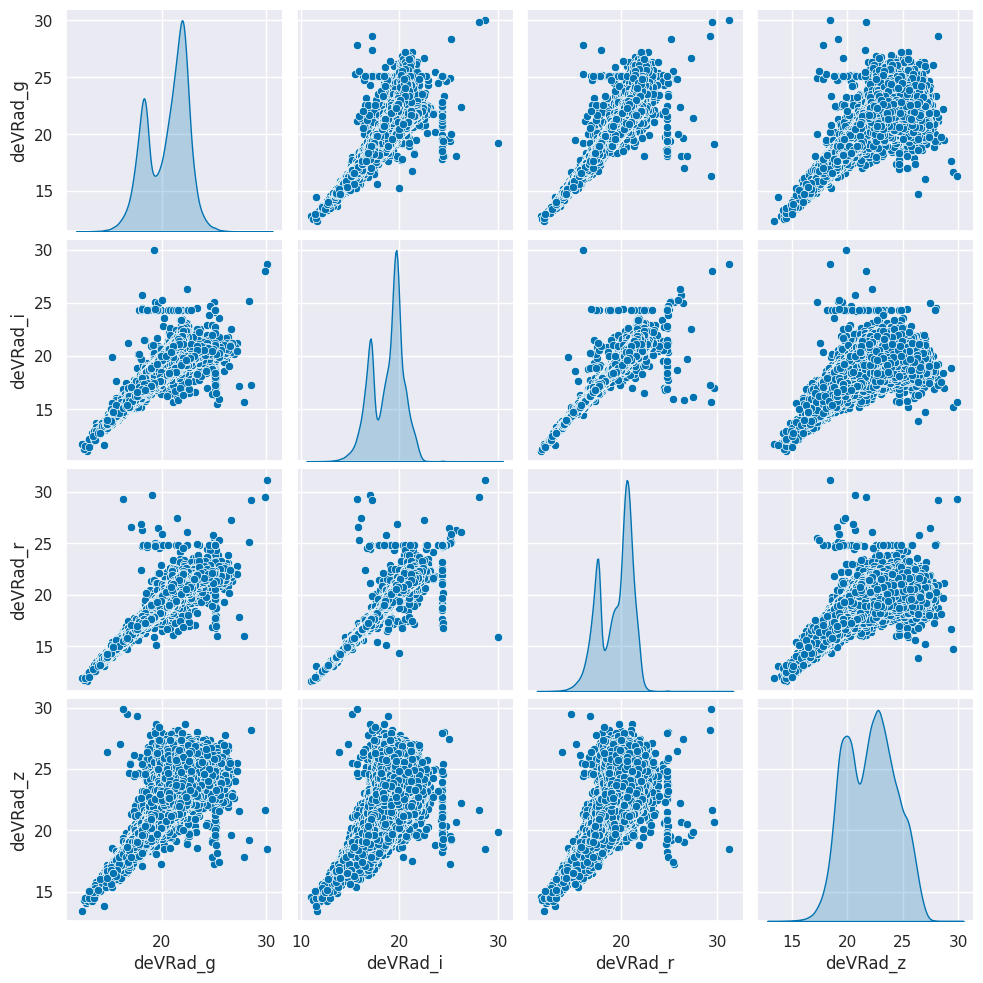

In [36]:
sns.pairplot(df_q['Morphological and Shape'].iloc[:, :4], diag_kind='kde')


- Se observan distribuciones bimodales en las 4 bandas, además de correlaciones positivas bastante marcadas 
- En segundo lugar, se observan segmentos (verticales y horizontales) donde una de las bandas presenta muy poca variabilidad respecto a las otra, tal vez debido a defectos de precisión de los instrumentos de medición

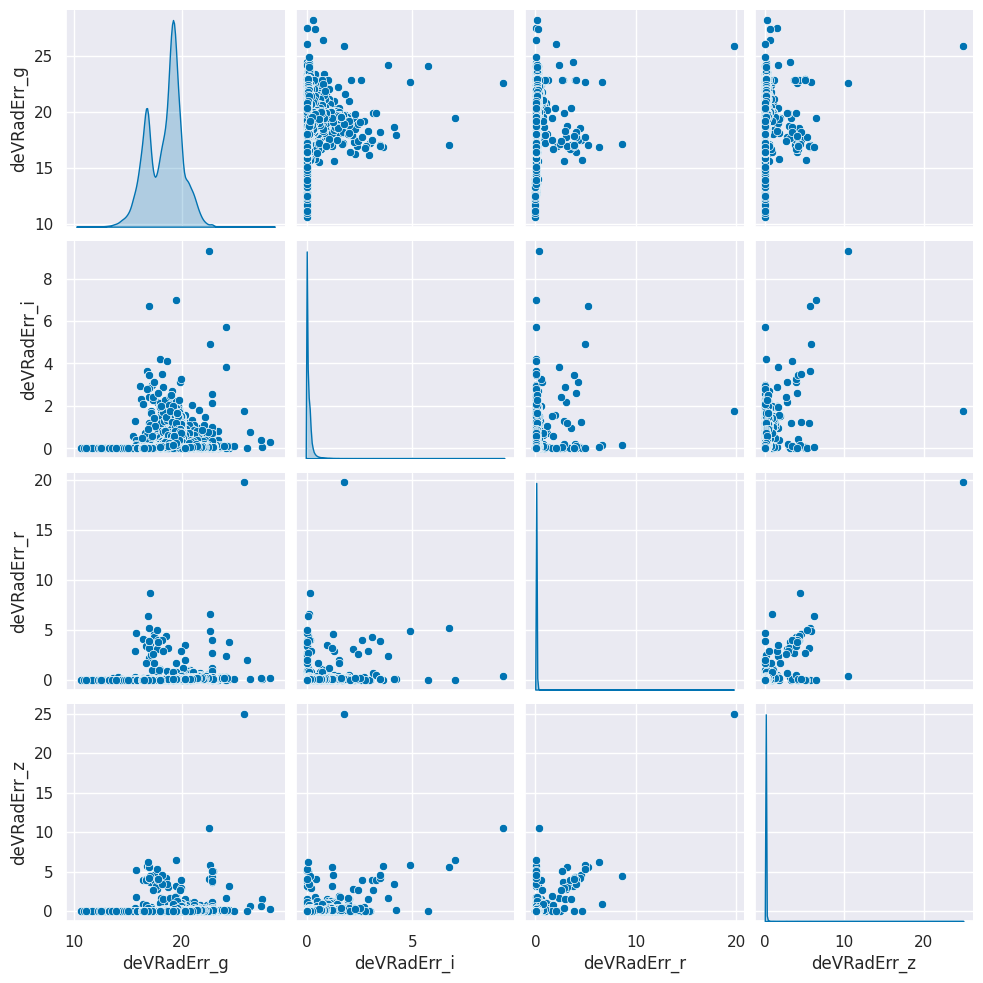

In [59]:
sns.pairplot(df_q['Morphological and Shape'].iloc[:, 4:8], diag_kind='kde')

- Distribución bimodal en la banda **g** y una fuerte influencia de outliers que impide visualizar la variabilidad de los valores cercanos a $0$ en las bandas **irz**

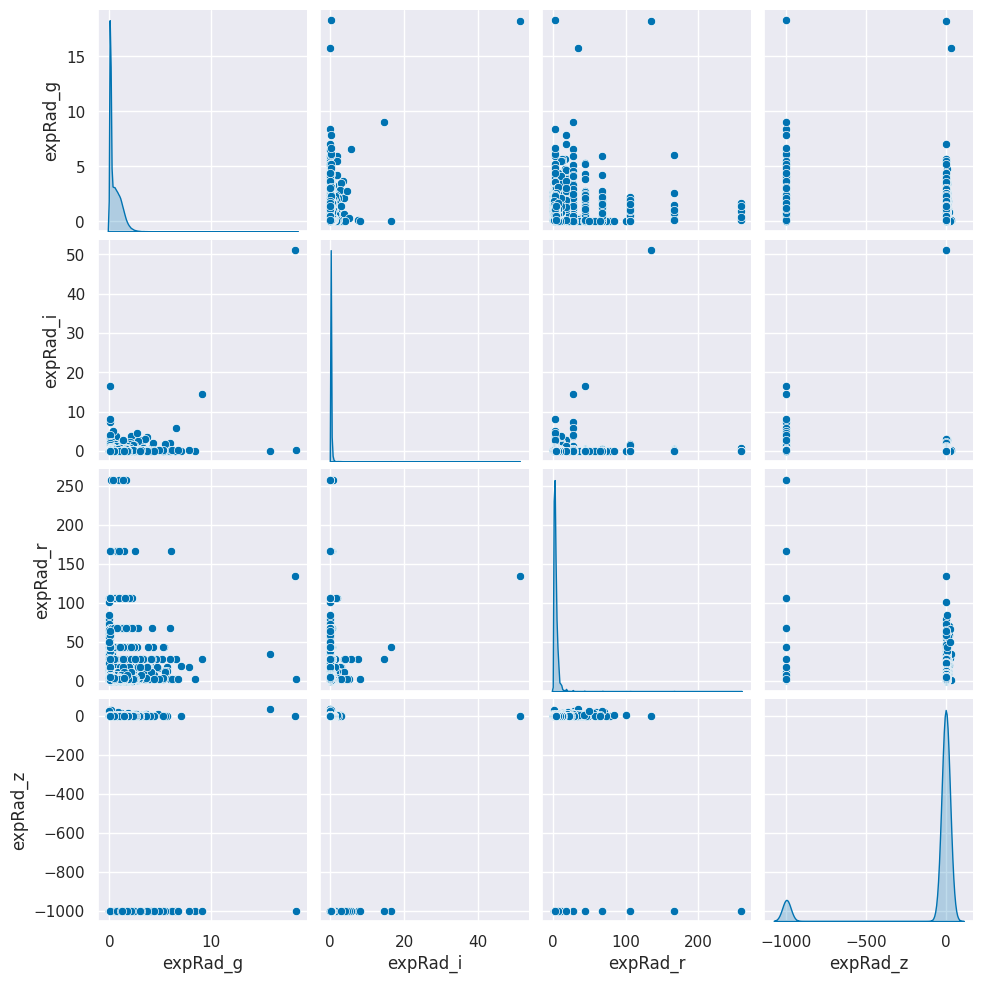

In [62]:
sns.pairplot(df_q['Morphological and Shape'].iloc[:, 8:12], diag_kind='kde')

- Mucha influencia de pocos outliers ubicados muy lejos de la media en las bandas **gir** 
- En la banda **z** se observa una distribución bimodal donde la segunda moda parece indicar presencia de valores artificiales en `-1000`. La falta de valores entre estas 2 modas y la baja variabilidad de los valores cercanos a `-1000` refuerza la hipótesis de que estos valores son realmente inconsistentes, no representativos y por tanto deberían ser descartados 

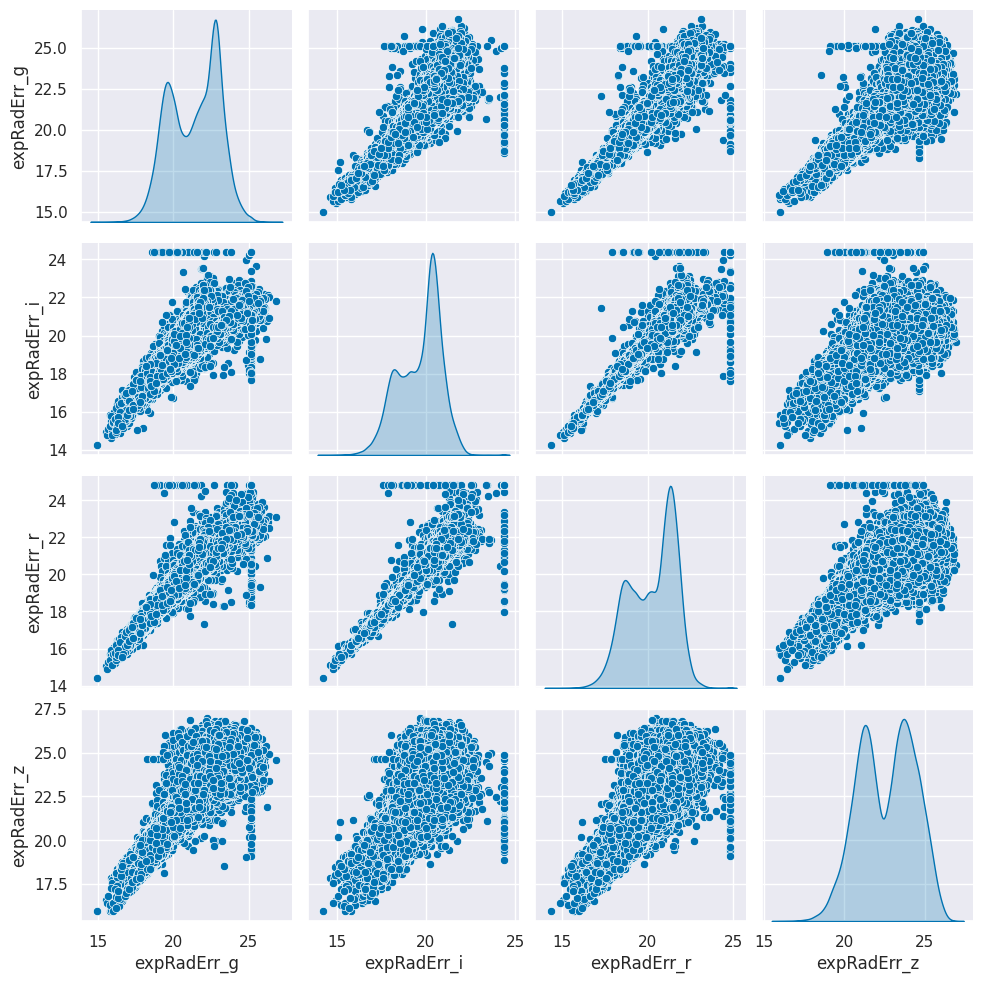

In [65]:
sns.pairplot(df_q['Morphological and Shape'].iloc[:, 12:16], diag_kind='kde')

- Distribuciones bimodales en todas las bandas, altas correlaciones positivas y gran similitud a las variables `deVRad`
- Poca influencia de outliers

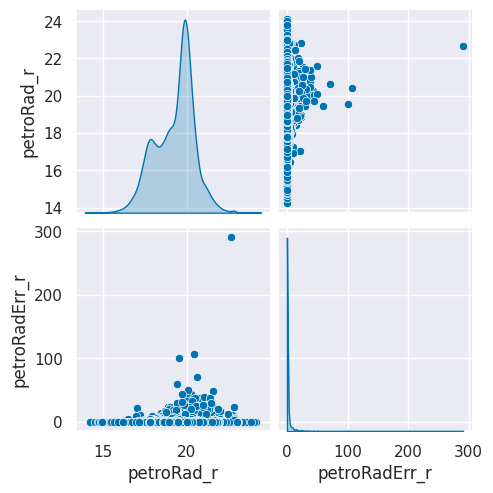

In [67]:
sns.pairplot(df_q['Morphological and Shape'].iloc[:, 16:18], diag_kind='kde')

- La variable de error presenta outliers que impiden visualizar su variabilidad en los valores cercanos a $0$
- La variable `petroRad` presenta una distribución bimodal con poca influencia de outliers

## Análisis individual

---
A continuación se procede a hacer un análisis puntual en las variables conflictivas, esto es, aquellas que presentaron:

1. Valores aparentemente artificiales
    - `expRad_z`
    - `dered_z`

2. Outliers muy lejanos de la moda ( $\gtrsim 10\sigma$)
    - `zErr`, `decErr`
    - `exntinction_giruz`
    - `fiberMag_g`, `fiberMag_i`, `fiberMagErr_r`, `fiberMagErr_u`, `fiberMagErr_z` 
    - `modelMag_giruz`
    - `modelMagErr_giruz`
    - `psfMagErr_giruz` 
    - `deVRadErr_irz`
    - `expRad_gir`
    - `petroRadErr`

- Filtrar outliers le permitirá a las diferentes redes que utilizarán estos datos, a tener una mejor estabilidad y rapidez de convergencia en el periodo de entrenamiento, contribuyendo a un modelamiento más robusto y preciso de las variables a predecir

In [3]:
# Definir dataframes para referirse de manera más directa a las variables de cada categoría
df_PR = df_q['Positional and Redshift']
df_MF = df_q['Magnitude and Flux Measurements']
df_MS = df_q['Morphological and Shape']

<Axes: xlabel='dered_z'>

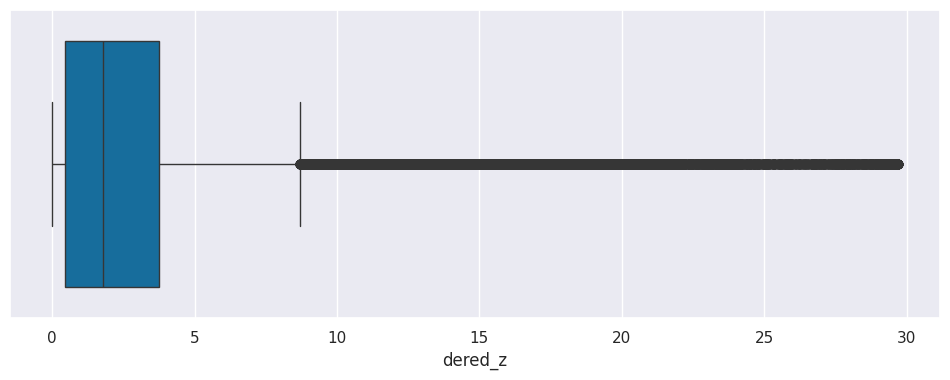

In [93]:
plt.figure(figsize=(12, 4))
#sns.violinplot(df_MF, x='dered_z')
sns.boxplot(df_MF, x='dered_z')

Se aprecia que existen outlier en todo el rango desde el whisker derecho hasta el valor máximo, por lo cual se decarta la hipótesis de valores articiales para esta variable

In [86]:
# Explorar distribución de outliers

Q1 = df_MF['dered_z'].quantile(.25)
Q3 = df_MF['dered_z'].quantile(.75)
IQR = Q3-Q1

In [103]:
# Contar outliers duplicados
print(df_MF[df_MF['dered_z'] > Q3 + 1.5*IQR ]['dered_z'].duplicated().sum())
# Quitar duplicados y evaluar distribuciión
dropped = df_MF[df_MF['dered_z'] > Q3 + 1.5*IQR ]['dered_z'].drop_duplicates()

1027


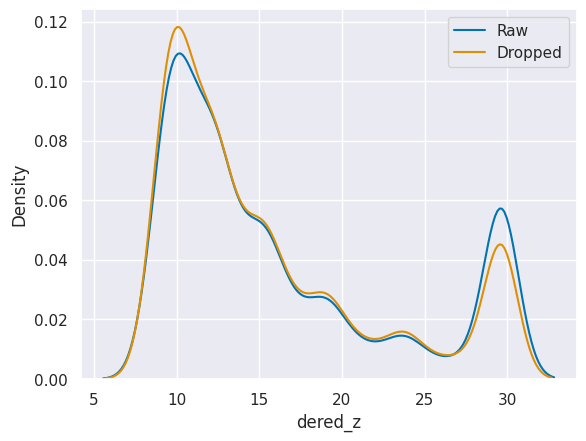

In [102]:
sns.kdeplot(df_MF[df_MF['dered_z'] > Q3 + 1.5*IQR ]['dered_z'], label='Raw')
sns.kdeplot(dropped, label='Dropped')
plt.legend()

- Se concluye que los valores duplicados no generan un cambio considerable en la distribución y por tanto no se filtran

<Axes: xlabel='expRad_z'>

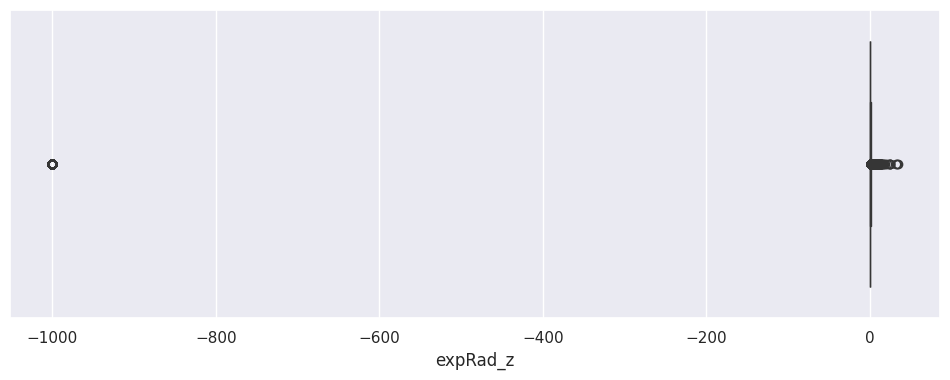

In [104]:
# expRad_z

plt.figure(figsize=(12, 4))
#sns.violinplot(df_MF, x='expRad_z')
sns.boxplot(df_MS, x='expRad_z')

- Se aprecia que los outliers situados en `-1000` están totalmente aislados del resto de valores, por tanto se asume que estos corresponden a valores articiales y por tanto descartables

In [7]:
# Contar y filtrar valores -1000

print(df_MS[df_MS['expRad_z'] == -1000]['expRad_z'].count())
df_2 = df_1[~(df_1==-1000).any(axis=1)].copy()
df_2

13658


,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
0,1.967009,0.001295,0.099945,0.004153,18.74923,18.55813,18.67467,18.87822,18.45218,0.091994,...,18.92338,19.15566,19.76303,18.72110,0.017365,0.015810,0.015986,0.029013,0.033841,57.405766
1,0.133383,0.000062,0.075584,0.009540,19.82256,18.39337,18.82100,21.98708,18.03142,0.833777,...,19.37808,19.95601,23.14468,18.83381,0.053584,0.083252,0.069951,0.343517,0.051267,57.488430
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


<Axes: xlabel='decErr'>

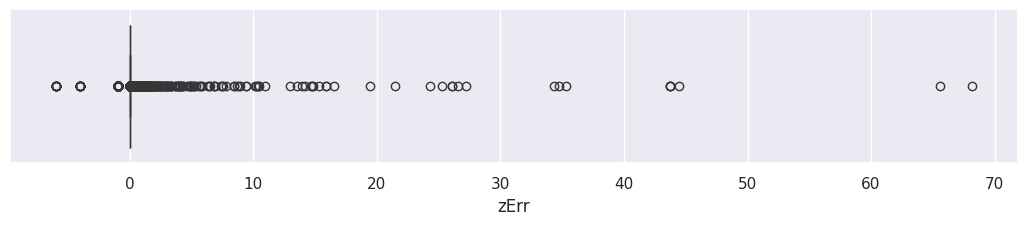

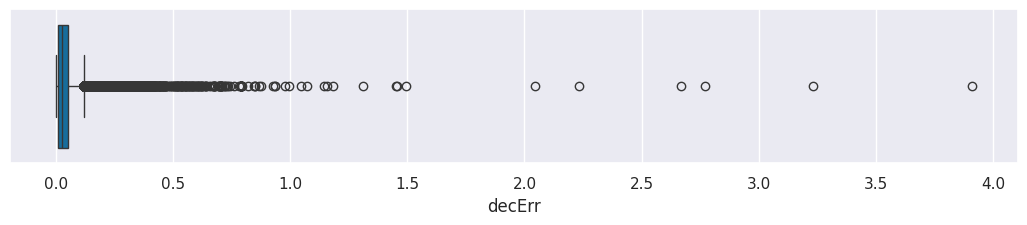

In [134]:
# zErr y decErr

plt.figure(figsize=(13,2))
sns.boxplot(df_2, x='zErr')
plt.figure(figsize=(13,2))
sns.boxplot(df_2, x='decErr')

<Axes: xlabel='extinction_z'>

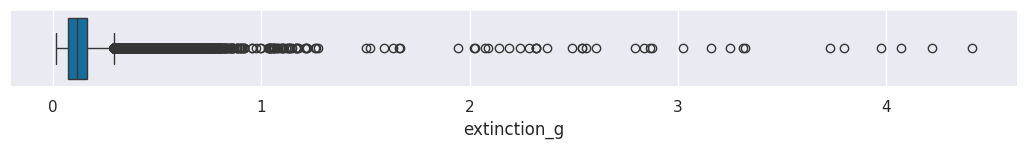

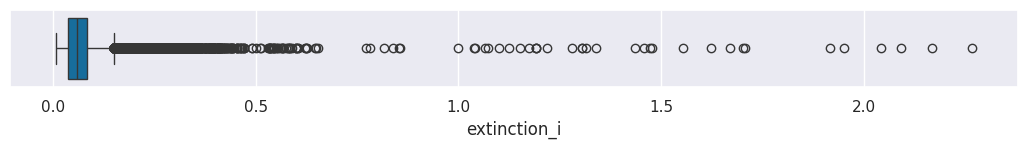

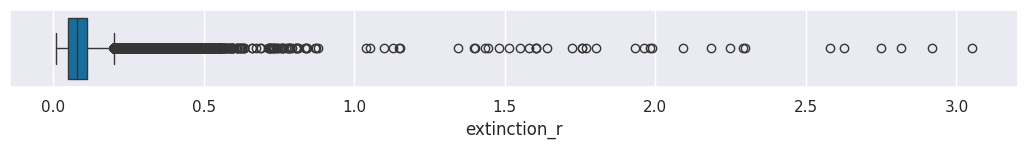

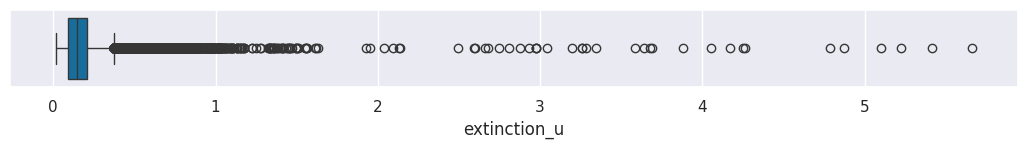

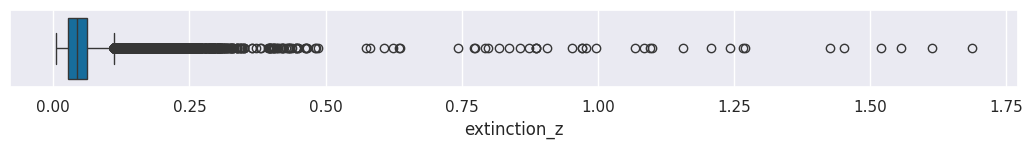

In [9]:
# extinction

plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='extinction_g')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='extinction_i')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='extinction_r')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='extinction_u')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='extinction_z')

- Tal como se observó anteriormente, la distribución de todas las variables de extinción es practicamente idéntica
- Se filtran los valores de manera consistente en todas las bandas

In [ ]:
df_2.columns.iloc[:, ]

Index(['z', 'zErr', 'dec', 'decErr', 'dered_g', 'dered_i', 'dered_r',
       'dered_u', 'dered_z', 'deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z',
       'deVRadErr_g', 'deVRadErr_i', 'deVRadErr_r', 'deVRadErr_z', 'expPhi_g',
       'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z', 'expRad_g', 'expRad_i',
       'expRad_r', 'expRad_z', 'expRadErr_g', 'expRadErr_i', 'expRadErr_r',
       'expRadErr_z', 'extinction_g', 'extinction_i', 'extinction_r',
       'extinction_u', 'extinction_z', 'fiberMag_g', 'fiberMag_i',
       'fiberMag_r', 'fiberMag_u', 'fiberMag_z', 'fiberMagErr_g',
       'fiberMagErr_i', 'fiberMagErr_r', 'fiberMagErr_u', 'fiberMagErr_z',
       'modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z',
       'modelMagErr_g', 'modelMagErr_i', 'modelMagErr_r', 'modelMagErr_u',
       'modelMagErr_z', 'petroRad_r', 'petroRadErr_r', 'psfMag_g', 'psfMag_i',
       'psfMag_r', 'psfMag_u', 'psfMag_z', 'psfMagErr_g', 'psfMagErr_i',
       'psfMagErr_r', 'psfMagErr_u', 

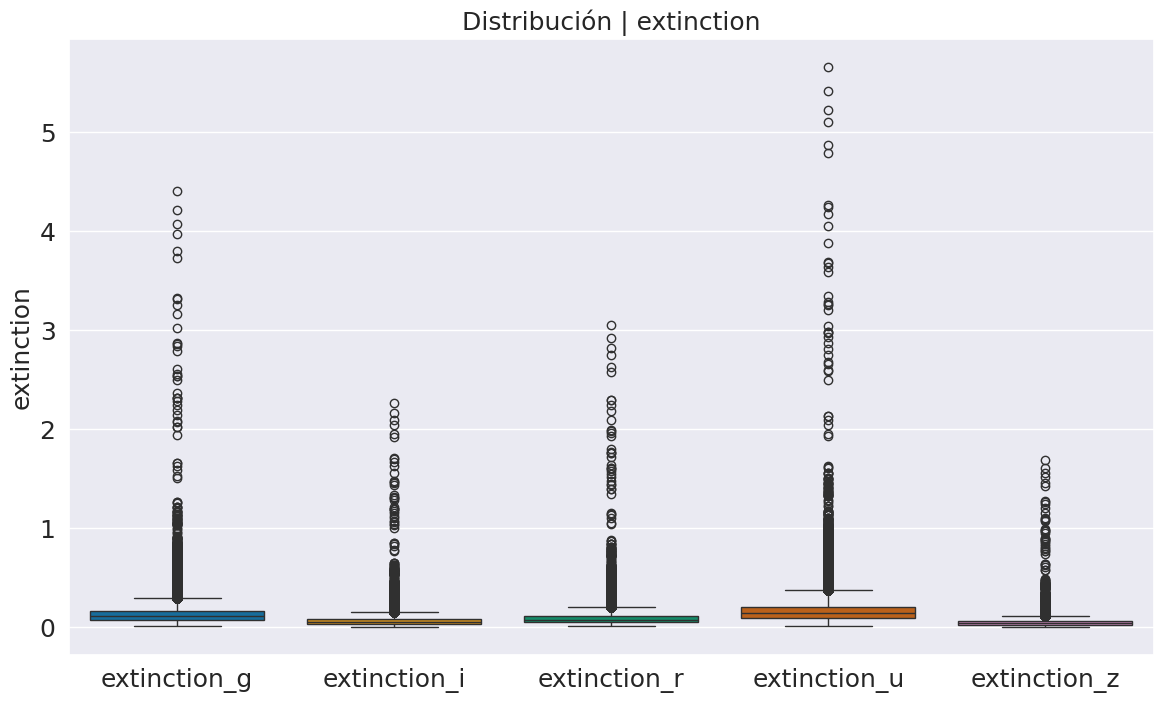

In [11]:
# Modifications-Post

fig, (ax_top) = plt.subplots(nrows=1, ncols=1,figsize=(14, 8))


sns.boxplot(df_2[['extinction_g','extinction_i','extinction_r','extinction_u','extinction_z']],
            ax=ax_top)

#ax_top.grid(True)
ax_top.set_title('Distribución | extinction', fontsize=18)
ax_top.tick_params(labelsize=18)
#ax_top.legend(frameon=True, shadow=True, fontsize=15, facecolor='#E9FF36', edgecolor='k', loc='upper left')
ax_top.set_ylabel('extinction', fontsize=18)
#ax_top.set_xlabel('Día relativo al evento', fontsize=16)
plt.savefig('extinction_boxplot_raw.png', dpi=300)

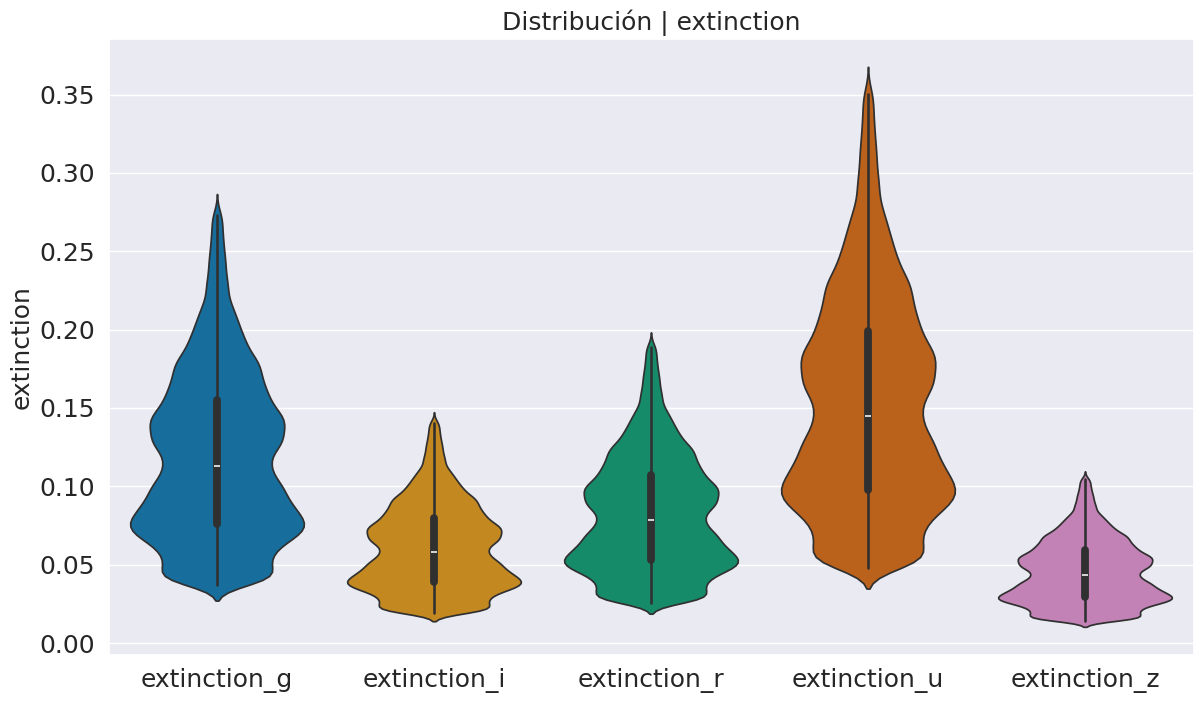

In [ ]:
df_ext = df_2[['extinction_g','extinction_i','extinction_r','extinction_u','extinction_z']]

# Filter
th = 0.95
df_ext_filtered = df_ext[(df_ext < df_ext.quantile(th)).all(axis=1) & (df_ext > df_ext.quantile(1-th)).all(axis=1)]

fig, (ax_top) = plt.subplots(nrows=1, ncols=1,figsize=(14, 8))

sns.violinplot(df_ext_filtered)

#ax_top.grid(True)
ax_top.set_title('Distribución | extinction', fontsize=18)
ax_top.tick_params(labelsize=18)
#ax_top.legend(frameon=True, shadow=True, fontsize=15, facecolor='#E9FF36', edgecolor='k', loc='upper left')
ax_top.set_ylabel('extinction', fontsize=18)
#ax_top.set_xlabel('Día relativo al evento', fontsize=16)

#plt.savefig('extinction_filtered95_violin.png', dpi=300)

In [15]:
# Filtrar outliers aislados
df_3 = df_2[((df_2['extinction_g'] < .5) & (df_2['extinction_g'] < .5) & (df_2['extinction_g'] < .5)
            & (df_2['extinction_g'] < .5) & ((df_2['extinction_g'] < .5)))].copy()
df_3

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
6,0.040547,0.000007,0.892603,0.010763,19.17722,18.51414,18.76188,20.24195,18.37012,1.062267,...,19.28752,19.67489,21.23447,19.08330,0.024857,0.018252,0.023442,0.077437,0.041859,55.110867
7,0.573384,0.000139,1.009484,0.067055,22.22190,19.45575,20.62989,25.65965,19.06060,2.122632,...,20.46578,21.78478,25.64097,19.90672,0.203310,0.072816,0.096167,0.791763,0.121874,55.185954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


<Axes: xlabel='fiberMag_i'>

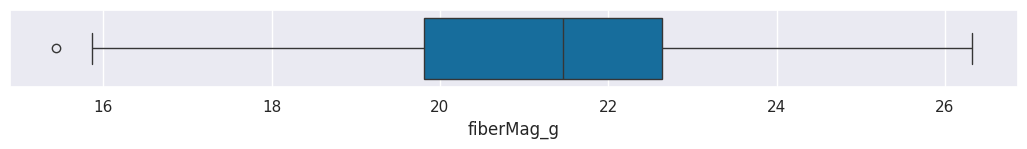

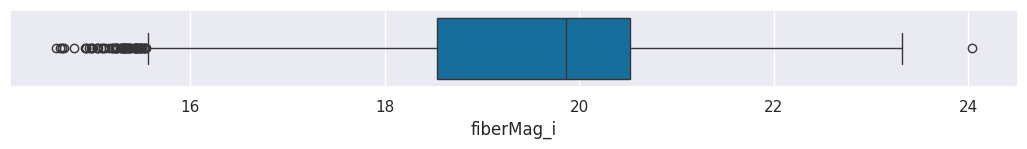

In [136]:
# fiberMag

plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='fiberMag_g')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='fiberMag_i')

- Se aprecia que al realizar el filtro anterior (df_1 -> df_2), los outliers de alto valor en estas variables, también fueron filtrados

<Axes: xlabel='fiberMagErr_z'>

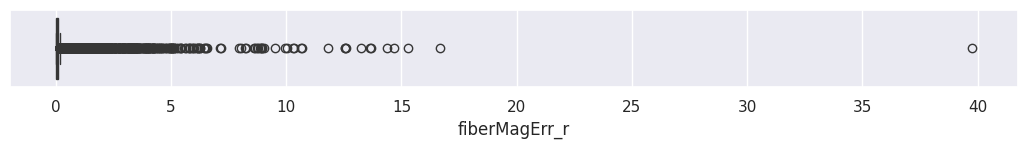

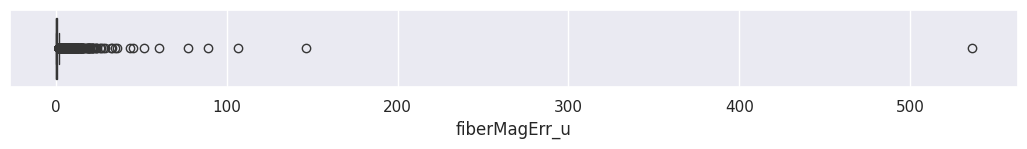

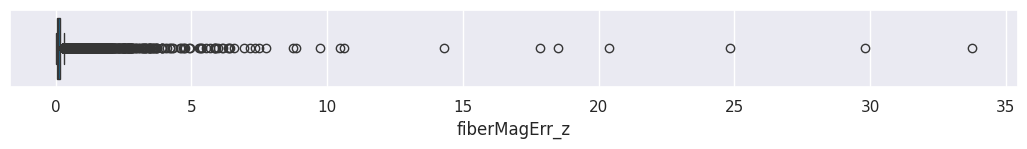

In [137]:
# fiberMagErr

plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='fiberMagErr_r')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='fiberMagErr_u')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='fiberMagErr_z')

- Nuevamente, bastante outliers aislados en esta variable

<Axes: xlabel='modelMag_z'>

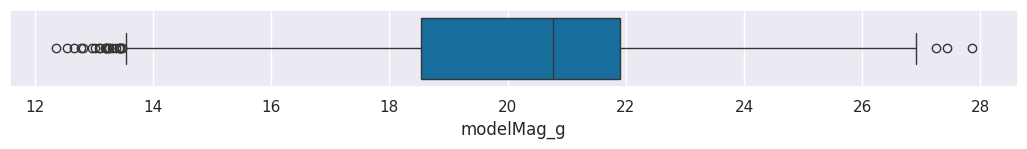

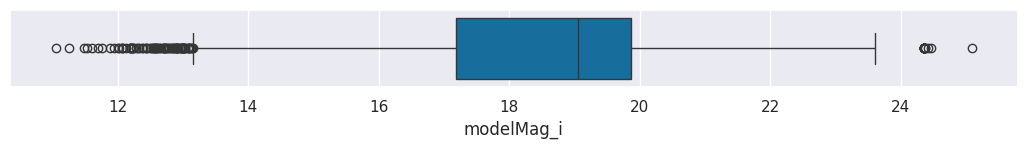

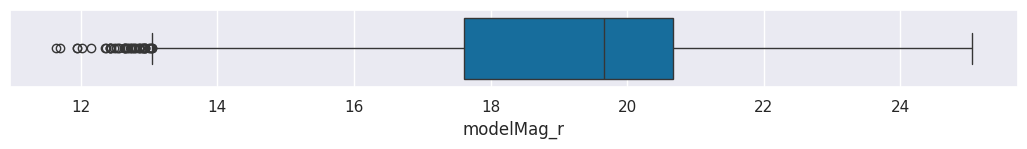

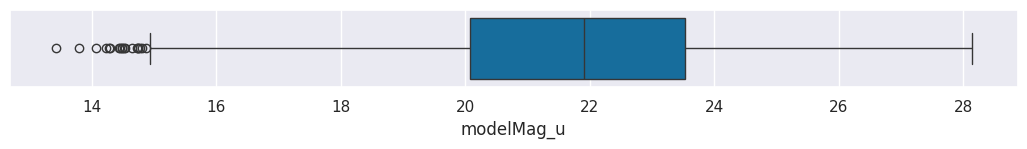

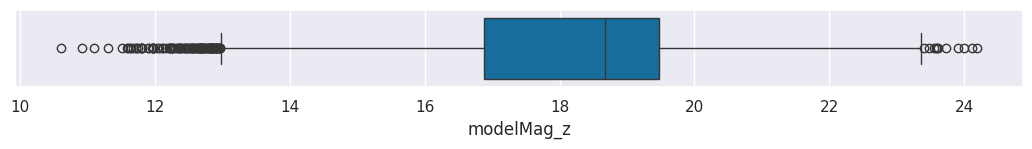

In [ ]:
# modelMag

plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='modelMag_g')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='modelMag_i')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='modelMag_r')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='modelMag_u')
plt.figure(figsize=(13,1))
sns.boxplot(df_2, x='modelMag_z')

- Se aprecia una cantidad considerable de outlier en todas las bandas excepto en **g** y **u**

<Axes: xlabel='modelMagErr_z'>

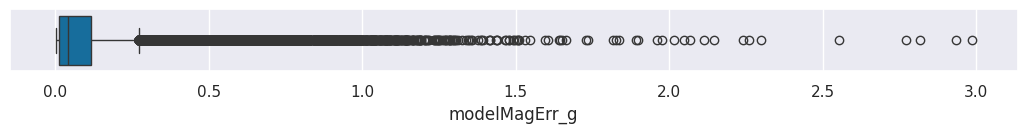

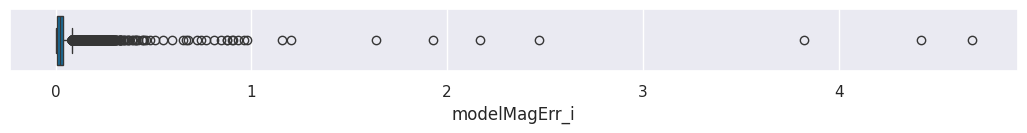

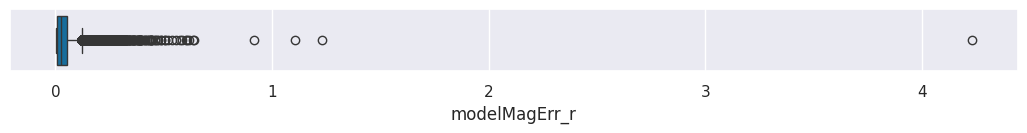

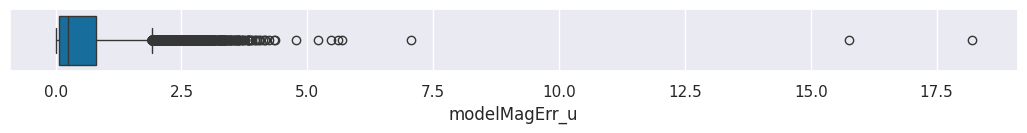

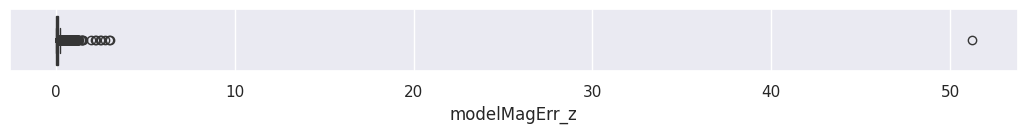

In [ ]:
# modelMagErr

plt.figure(figsize=(13,.8))
sns.boxplot(df_2, x='modelMagErr_g')
plt.figure(figsize=(13,.8))
sns.boxplot(df_2, x='modelMagErr_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_2, x='modelMagErr_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_2, x='modelMagErr_u')
plt.figure(figsize=(13,.8))
sns.boxplot(df_2, x='modelMagErr_z')

- Se observan valores muy aislados incluso respecto a los outliers, por tanto se decide filtrarlos

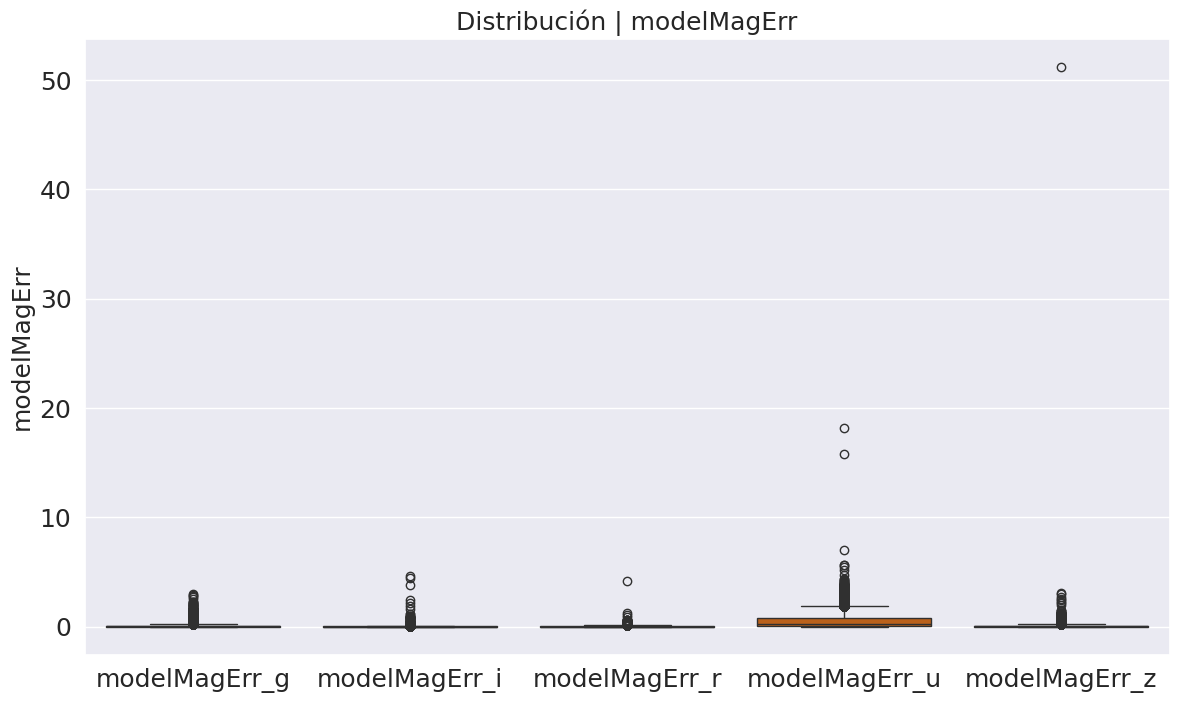

In [13]:
# Modifications-Post

fig, (ax_top) = plt.subplots(nrows=1, ncols=1,figsize=(14, 8))


sns.boxplot(df_2[['modelMagErr_g','modelMagErr_i','modelMagErr_r','modelMagErr_u','modelMagErr_z']],
            ax=ax_top)

#ax_top.grid(True)
ax_top.set_title('Distribución | modelMagErr', fontsize=18)
ax_top.tick_params(labelsize=18)
#ax_top.legend(frameon=True, shadow=True, fontsize=15, facecolor='#E9FF36', edgecolor='k', loc='upper left')
ax_top.set_ylabel('modelMagErr', fontsize=18)
#ax_top.set_xlabel('Día relativo al evento', fontsize=16)
plt.savefig('modelMagErr_boxplot_raw.png', dpi=300)

In [16]:
# Filtrar outliers aislados
df_4 = df_3[((df_3['modelMagErr_i'] < 1.) & (df_3['modelMagErr_r'] < 0.75)
            & (df_3['modelMagErr_u'] < 5.) & ((df_3['modelMagErr_z'] < 50)))].copy()
df_4

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
6,0.040547,0.000007,0.892603,0.010763,19.17722,18.51414,18.76188,20.24195,18.37012,1.062267,...,19.28752,19.67489,21.23447,19.08330,0.024857,0.018252,0.023442,0.077437,0.041859,55.110867
7,0.573384,0.000139,1.009484,0.067055,22.22190,19.45575,20.62989,25.65965,19.06060,2.122632,...,20.46578,21.78478,25.64097,19.90672,0.203310,0.072816,0.096167,0.791763,0.121874,55.185954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


<Axes: xlabel='modelMagErr_z'>

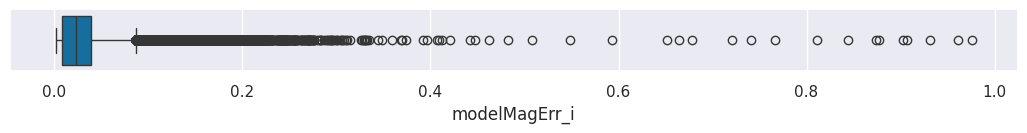

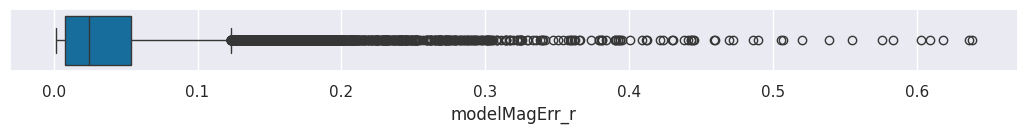

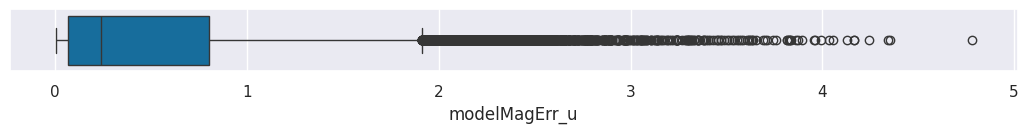

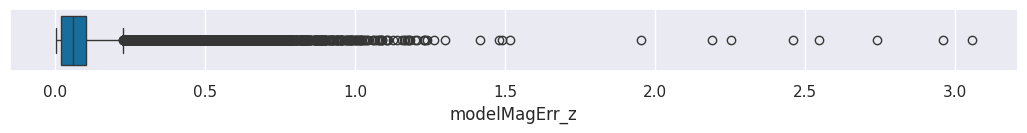

In [150]:
# Verificar
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='modelMagErr_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='modelMagErr_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='modelMagErr_u')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='modelMagErr_z')

- Ahora las distancias entre los outliers son comparables con los rangos intercuartiles

Text(0, 0.5, 'modelMagErr')

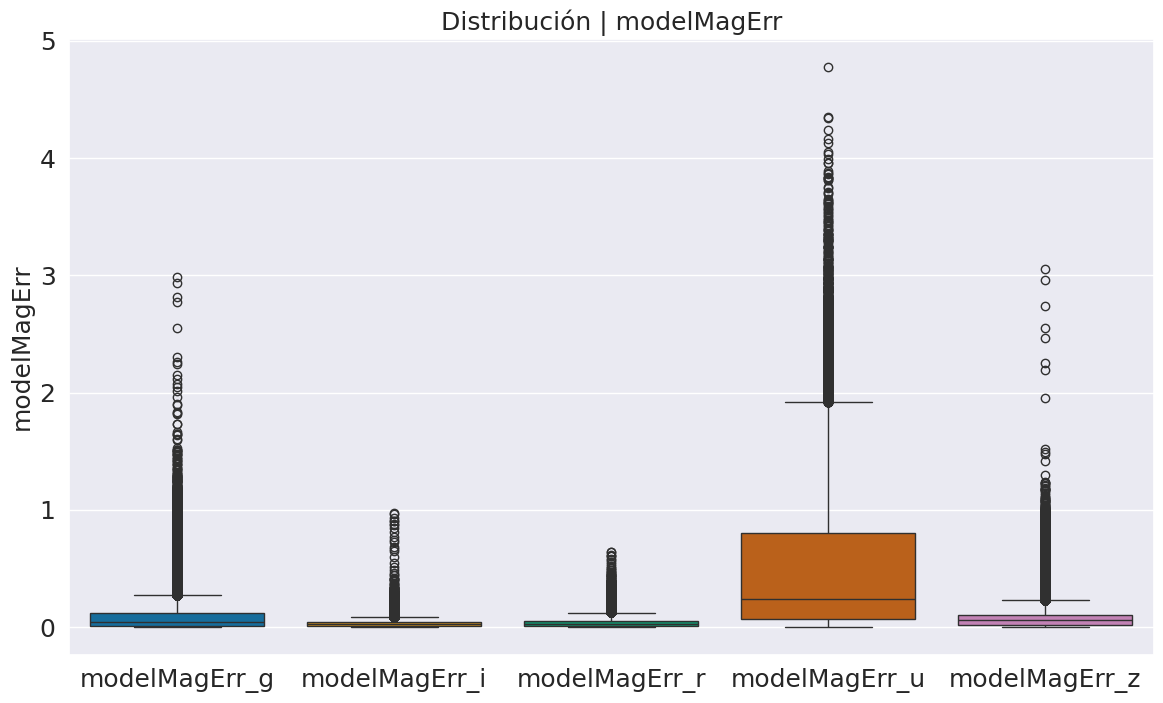

In [17]:
# Modifications-Post

fig, (ax_top) = plt.subplots(nrows=1, ncols=1,figsize=(14, 8))


sns.boxplot(df_4[['modelMagErr_g','modelMagErr_i','modelMagErr_r','modelMagErr_u','modelMagErr_z']],
            ax=ax_top)

#ax_top.grid(True)
ax_top.set_title('Distribución | modelMagErr', fontsize=18)
ax_top.tick_params(labelsize=18)
#ax_top.legend(frameon=True, shadow=True, fontsize=15, facecolor='#E9FF36', edgecolor='k', loc='upper left')
ax_top.set_ylabel('modelMagErr', fontsize=18)
#ax_top.set_xlabel('Día relativo al evento', fontsize=16)
#plt.savefig('modelMagErr_boxplot_filtered.png', dpi=300)

<Axes: xlabel='psfMagErr_z'>

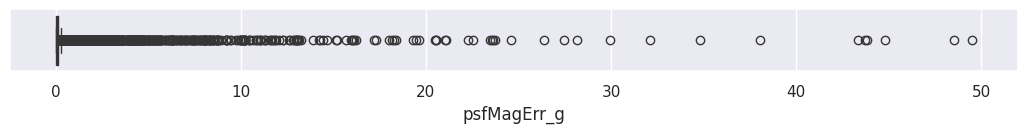

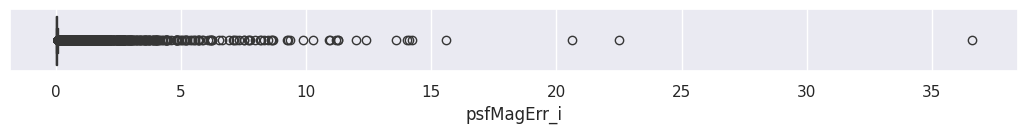

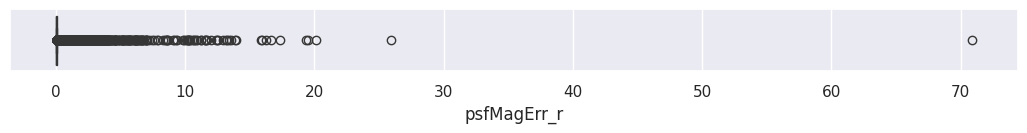

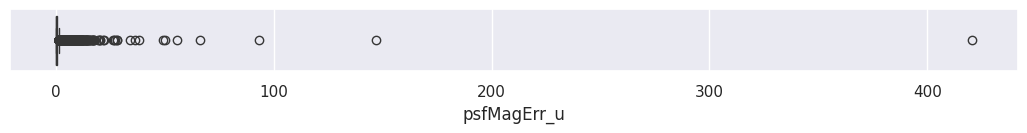

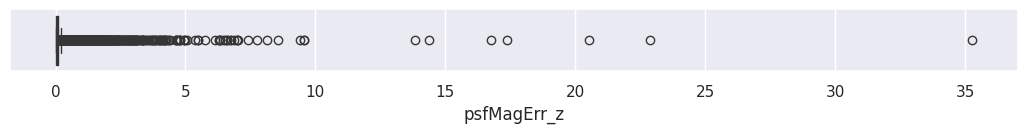

In [151]:
# psfMagErr

plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='psfMagErr_g')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='psfMagErr_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='psfMagErr_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='psfMagErr_u')
plt.figure(figsize=(13,.8))
sns.boxplot(df_3, x='psfMagErr_z')

- Se procede de manera similar al caso anterior

In [221]:
# filtrar outliers aislados
df_5 = df_4[((df_4['psfMagErr_g'] < 12.5) & (df_4['psfMagErr_i'] < 6)
            & (df_4['psfMagErr_r'] < 7) & ((df_4['psfMagErr_u'] < 40))
            & ((df_4['psfMagErr_z'] < 5.5)))].copy()
df_5

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
6,0.040547,0.000007,0.892603,0.010763,19.17722,18.51414,18.76188,20.24195,18.37012,1.062267,...,19.28752,19.67489,21.23447,19.08330,0.024857,0.018252,0.023442,0.077437,0.041859,55.110867
7,0.573384,0.000139,1.009484,0.067055,22.22190,19.45575,20.62989,25.65965,19.06060,2.122632,...,20.46578,21.78478,25.64097,19.90672,0.203310,0.072816,0.096167,0.791763,0.121874,55.185954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


<Axes: xlabel='psfMagErr_z'>

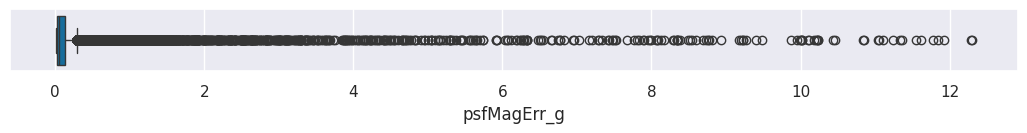

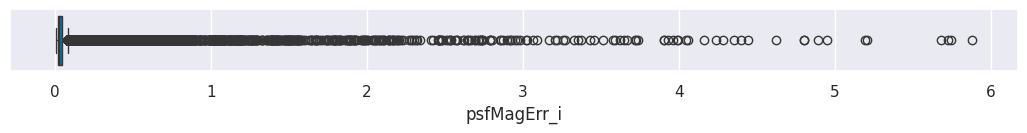

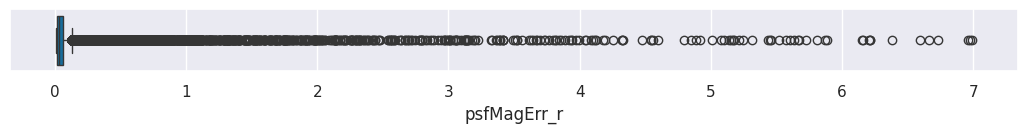

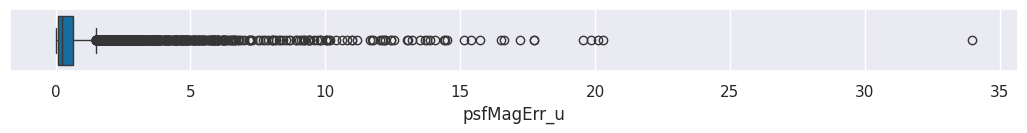

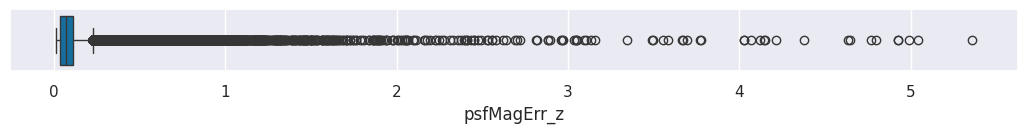

In [155]:
# Verificar
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='psfMagErr_g')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='psfMagErr_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='psfMagErr_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='psfMagErr_u')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='psfMagErr_z')

<Axes: xlabel='deVRadErr_z'>

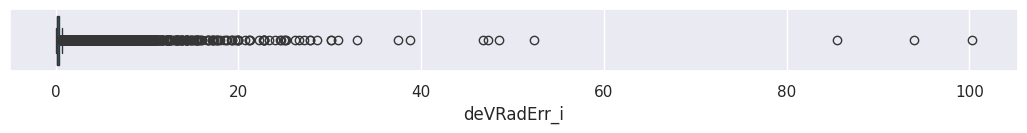

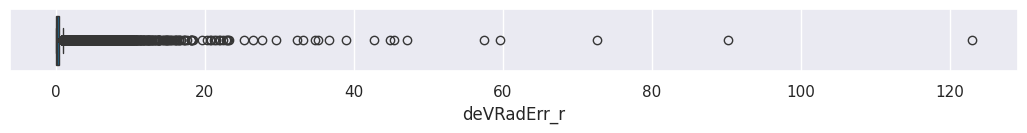

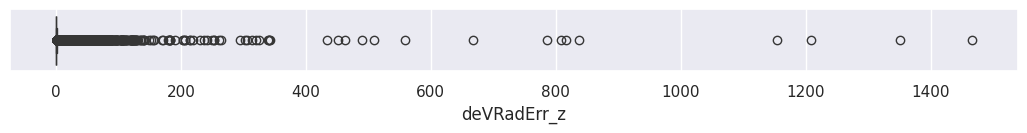

In [ ]:
# deVRadErr

plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='deVRadErr_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='deVRadErr_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_4, x='deVRadErr_z')

In [222]:
# filtrar outliers aislados
df_6 = df_5[((df_5['deVRadErr_i'] < 20) & (df_5['deVRadErr_r'] < 20)
            & (df_5['deVRadErr_z'] < 70))].copy()
df_6

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
6,0.040547,0.000007,0.892603,0.010763,19.17722,18.51414,18.76188,20.24195,18.37012,1.062267,...,19.28752,19.67489,21.23447,19.08330,0.024857,0.018252,0.023442,0.077437,0.041859,55.110867
7,0.573384,0.000139,1.009484,0.067055,22.22190,19.45575,20.62989,25.65965,19.06060,2.122632,...,20.46578,21.78478,25.64097,19.90672,0.203310,0.072816,0.096167,0.791763,0.121874,55.185954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


<Axes: xlabel='petroRadErr_r'>

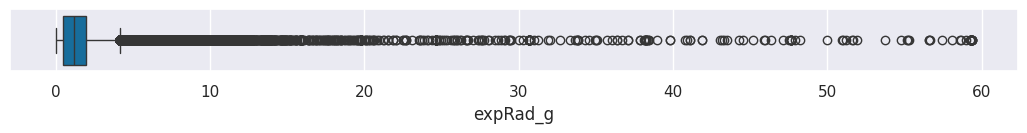

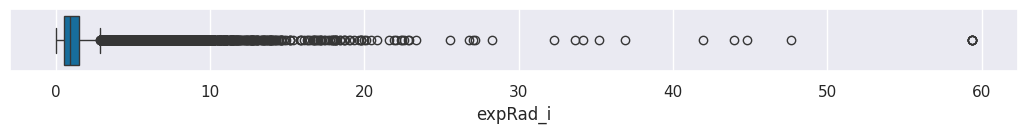

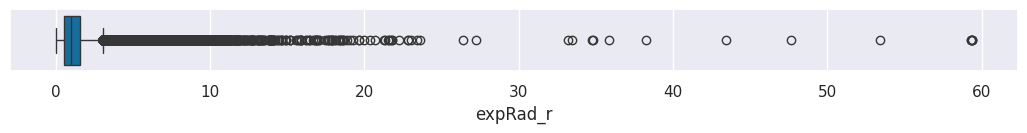

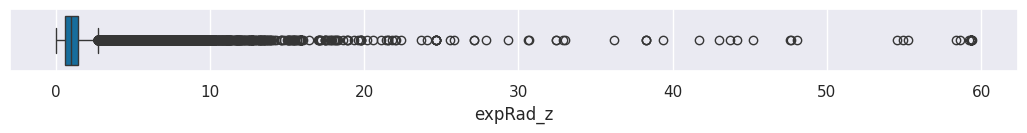

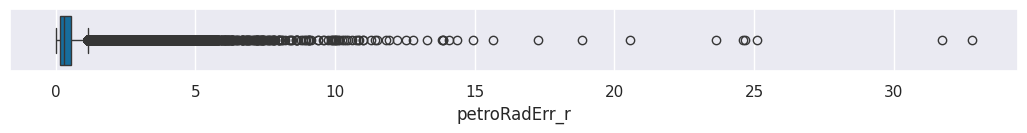

In [197]:
# expRad

plt.figure(figsize=(13,.8))
sns.boxplot(df_5, x='expRad_g')
plt.figure(figsize=(13,.8))
sns.boxplot(df_5, x='expRad_i')
plt.figure(figsize=(13,.8))
sns.boxplot(df_5, x='expRad_r')
plt.figure(figsize=(13,.8))
sns.boxplot(df_5, x='expRad_z')

# petroRadErr
plt.figure(figsize=(13,.8))
sns.boxplot(df_5, x='petroRadErr_r')

- En este caso solo se filtra sobre todas las variables `expRad` para que la variabilidad entre ellas sea comparable
- Además, se filtran los outliers aislados en `petroRadErr_r`

In [223]:
# filtrar outliers aislados
df_7 = df_6[((df_6['expRad_g'] < 10) & (df_6['expRad_i'] < 10) & (df_6['expRad_r'] < 10) 
            & (df_6['expRad_z'] < 10) & (df_6['petroRadErr_r'] < 12))].copy()
df_7

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
5,0.097569,0.000006,1.042906,0.026284,18.46132,17.72714,18.05147,19.86415,17.57771,6.613372,...,19.26304,19.74532,21.62152,19.00760,0.025899,0.025018,0.023596,0.104282,0.044190,55.025015
6,0.040547,0.000007,0.892603,0.010763,19.17722,18.51414,18.76188,20.24195,18.37012,1.062267,...,19.28752,19.67489,21.23447,19.08330,0.024857,0.018252,0.023442,0.077437,0.041859,55.110867
7,0.573384,0.000139,1.009484,0.067055,22.22190,19.45575,20.62989,25.65965,19.06060,2.122632,...,20.46578,21.78478,25.64097,19.90672,0.203310,0.072816,0.096167,0.791763,0.121874,55.185954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149996,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149997,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149998,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


In [224]:
# Muestras filtradas
len(df_raw) - len(df_7)

15942

- De esta forma se concluye la detección y filtro de outliers y valores incosistentes (i.e., -1000 y -9999)
- Luego de aplicar 7 filtros, se mantuvieron **134058** muestras de un total de 150000, por lo cual se filtró cerca del 11% de las muestras originales

---
Explorar valores atípicos en los primeros momentos estadísticos

In [ ]:
# Calcular primeros momentos para todas las variables

kurtosis = df_7.kurtosis(numeric_only=True)
skewness = df_7.skew(numeric_only=True)
mean = df_7.mean(numeric_only=True)
variance = df_7.var(numeric_only=True)

# Construir dataframe 
moments = pd.DataFrame({'Mean': mean, 'Variance': variance, 'Skewness': skewness, 'Kurtosis': kurtosis})
moments

,Mean,Variance,Skewness,Kurtosis
z,0.624618,0.503532,2.140807,4.772043
zErr,0.008350,0.227476,84.038216,8985.204065
dec,26.119692,748.544921,0.183545,-1.758430
decErr,0.039807,0.002510,13.174938,608.157848
dered_g,20.198158,3.745863,-0.323213,-0.810508
...,...,...,...,...
psfMagErr_i,0.047891,0.015824,19.903349,550.068130
psfMagErr_r,0.057339,0.028133,20.401002,550.398531
psfMagErr_u,0.389746,0.235785,12.940422,439.375334
psfMagErr_z,0.094643,0.017877,11.239597,251.466035


Text(0, 0.5, 'Variance')

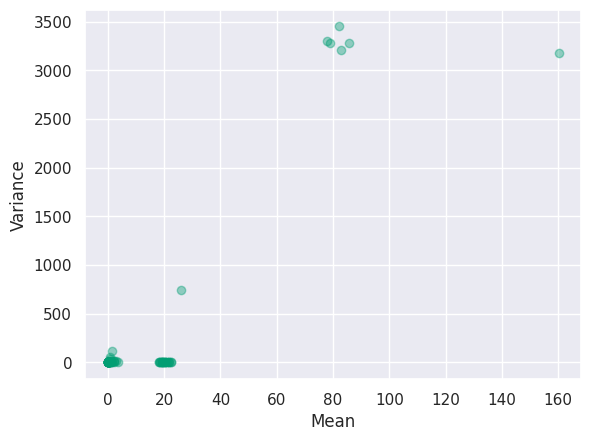

In [211]:
plt.plot(moments['Mean'], moments['Variance'], 'go', alpha=.4)
plt.xlabel('Mean')
plt.ylabel('Variance')

- Se identifican 6 variables con valores bastante alejados del resto

In [204]:
# Variables con alta varianza
moments[moments['Variance']>3000]

,Mean,Variance,Skewness,Kurtosis
expPhi_g,77.910726,3298.470655,0.176039,-0.478428
expPhi_i,82.686139,3211.058970,0.040519,-0.392817
expPhi_r,85.530743,3282.201692,-0.012275,-0.419015
expPhi_u,82.061781,3451.468959,0.036304,-0.552576
expPhi_z,78.863713,3283.703683,0.046260,-0.463079
ra,160.223845,3178.064098,-0.623022,0.329718


- Así, se tiene que uno de estos altos valores de varianza corresponde a `ra` y el resto a variables `expPhi`
- A continuación se realiza una visualización comparativa entre las bandas de cada variable  

## Visualización por variable

- Estructura general de las siguientes celdas:

    1. Selección de variables
    2. Configuración de la gráfica: linestyle, linediwth, fontsize, labels
    3. Visualización: utilizando la función `sns.kdeplot`

- Notar que todas estas visualizaciones se realizan sobre el último dataframe filtrado    

### expPhi 

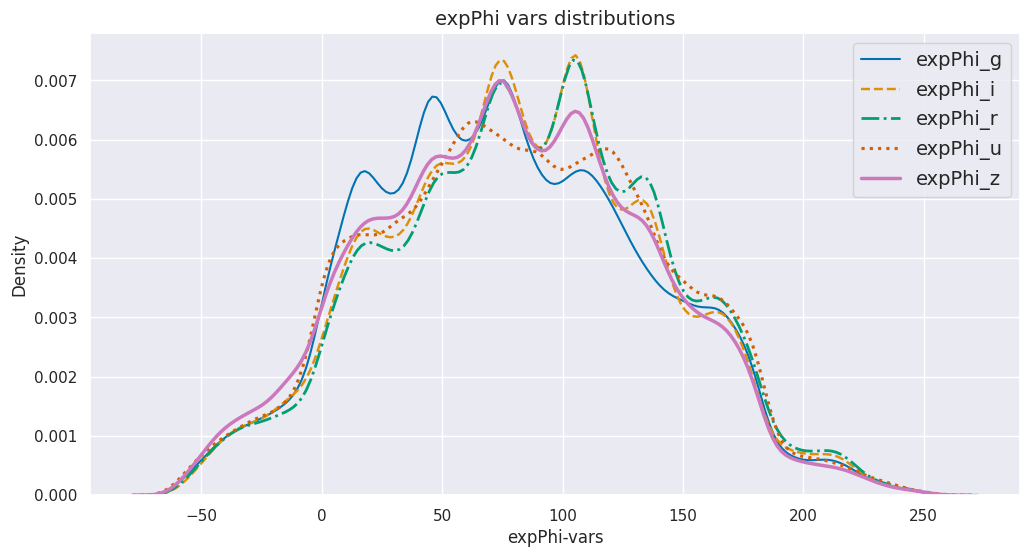

In [ ]:
# Visualizar distribuciones

vars = moments[moments['Variance']>3000].drop(['ra']).index         # considera todas las variables expPhi
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('expPhi vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('expPhi-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/expPhi_KDE.png', dpi=400)

### psfMag

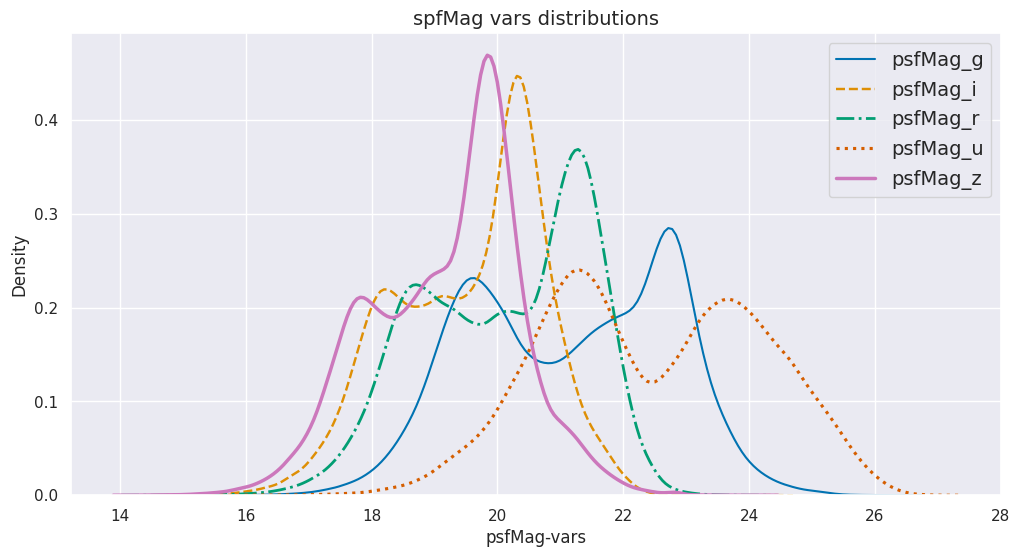

In [ ]:
vars = ['psfMag_g', 'psfMag_i', 'psfMag_r', 'psfMag_u', 'psfMag_z']
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('spfMag vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('psfMag-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/spfMag_KDE.png', dpi=400)

In [102]:
df_clean.columns

Index(['z', 'zErr', 'dec', 'decErr', 'dered_g', 'dered_i', 'dered_r',
       'dered_u', 'dered_z', 'deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z',
       'deVRadErr_g', 'deVRadErr_i', 'deVRadErr_r', 'deVRadErr_z', 'expPhi_g',
       'expPhi_i', 'expPhi_r', 'expPhi_u', 'expPhi_z', 'expRad_g', 'expRad_i',
       'expRad_r', 'expRad_z', 'expRadErr_g', 'expRadErr_i', 'expRadErr_r',
       'expRadErr_z', 'extinction_g', 'extinction_i', 'extinction_r',
       'extinction_u', 'extinction_z', 'fiberMag_g', 'fiberMag_i',
       'fiberMag_r', 'fiberMag_u', 'fiberMag_z', 'fiberMagErr_g',
       'fiberMagErr_i', 'fiberMagErr_r', 'fiberMagErr_u', 'fiberMagErr_z',
       'modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z',
       'modelMagErr_g', 'modelMagErr_i', 'modelMagErr_r', 'modelMagErr_u',
       'modelMagErr_z', 'petroRad_r', 'petroRadErr_r', 'psfMag_g', 'psfMag_i',
       'psfMag_r', 'psfMag_u', 'psfMag_z', 'psfMagErr_g', 'psfMagErr_i',
       'psfMagErr_r', 'psfMagErr_u', 

### deVRad

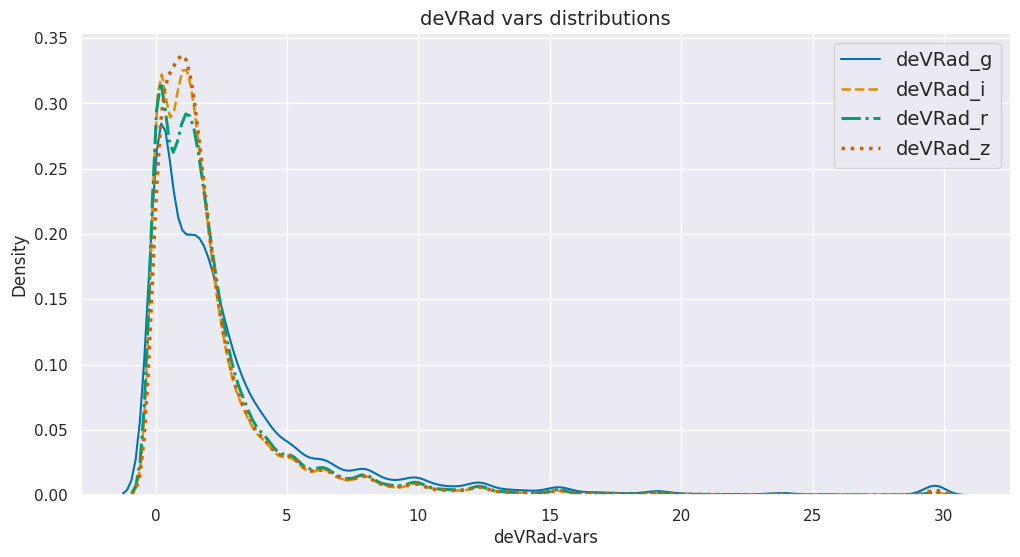

In [ ]:
vars = ['deVRad_g', 'deVRad_i', 'deVRad_r', 'deVRad_z']
styles = ['-', '--', '-.', ':']
lws = np.linspace(1.5, 2.5, 4)

plt.figure(figsize=(12,6)); fs=14
plt.title('deVRad vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('deVRad-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/deVRad_KDE.png', dpi=400)

- Esta moda cercana a 30 está presente en todas las bandas, aunque en mayor medida en la banda **g**, por tanto se intuye que podría tratarse de un defecto común en el modo en que esta variable está siendo medida

### fiberMag

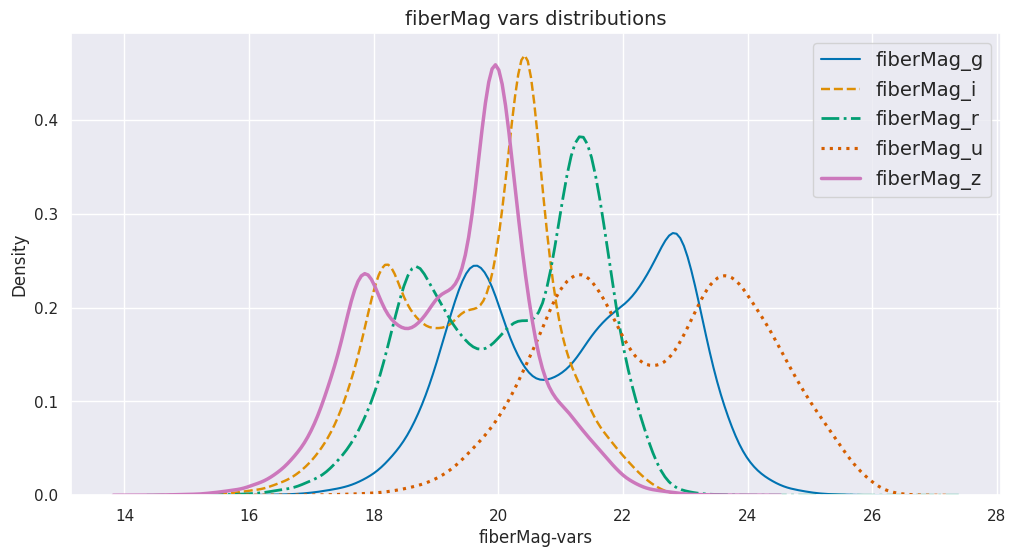

In [ ]:
vars = ['fiberMag_g', 'fiberMag_i',
       'fiberMag_r', 'fiberMag_u', 'fiberMag_z']
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('fiberMag vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('fiberMag-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/fiberMag_KDE.png', dpi=400)

### dered

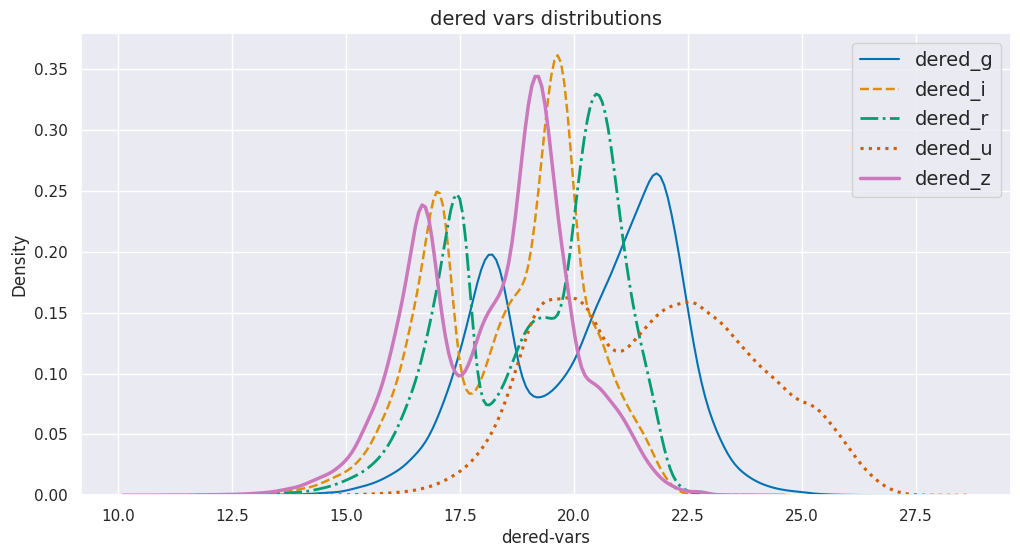

In [ ]:
vars = ['dered_g', 'dered_i', 'dered_r',
       'dered_u', 'dered_z']
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('dered vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('dered-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/dered_KDE.png', dpi=400)

### modelMag

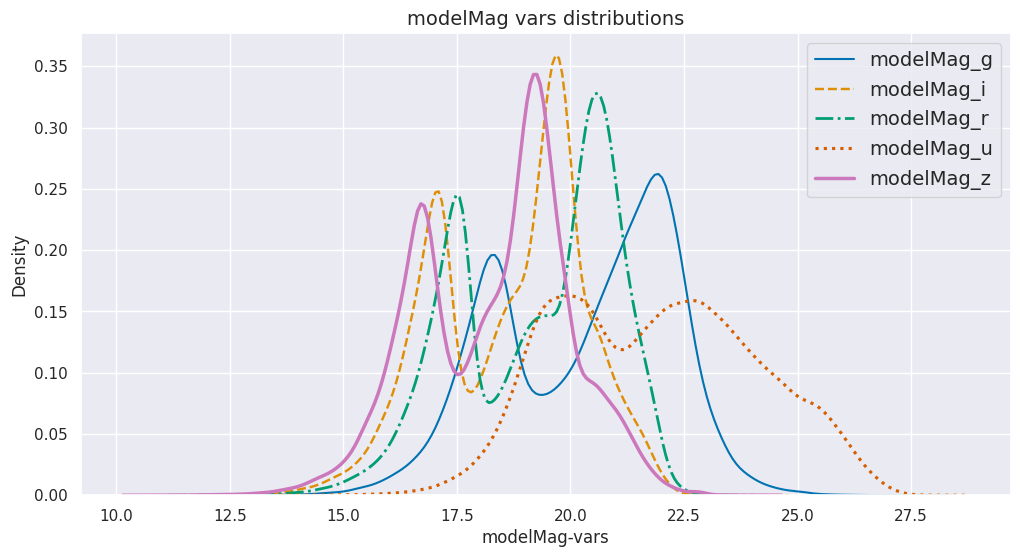

In [195]:
vars = ['modelMag_g', 'modelMag_i', 'modelMag_r', 'modelMag_u', 'modelMag_z']
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('modelMag vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_6, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('modelMag-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/modelMag_KDE.png', dpi=400)

### expRad

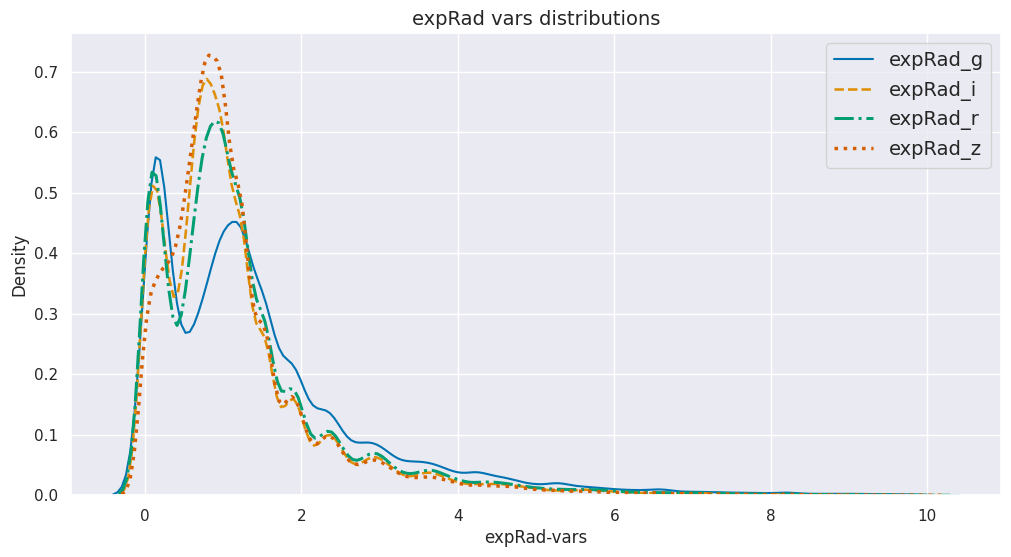

In [227]:
vars = ['expRad_g', 'expRad_i',
       'expRad_r', 'expRad_z']
styles = ['-', '--', '-.', ':']
lws = np.linspace(1.5, 2.5, 4)

plt.figure(figsize=(12,6)); fs=14
plt.title('expRad vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('expRad-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/expRad_KDE.png', dpi=400)

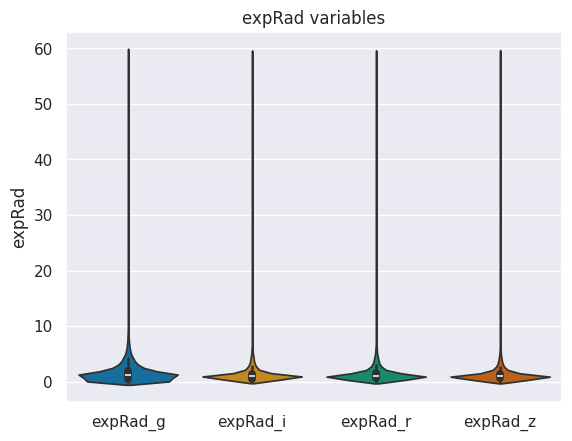

In [ ]:
## further analyze expRad

df_expRad = df_clean[['expRad_g', 'expRad_i','expRad_r', 'expRad_z']]

plt.title('expRad variables');
plt.ylabel('expRad')
sns.violinplot(data=df_expRad)

#plt.savefig('../IMG/expRad_violin.png', dpi=300)

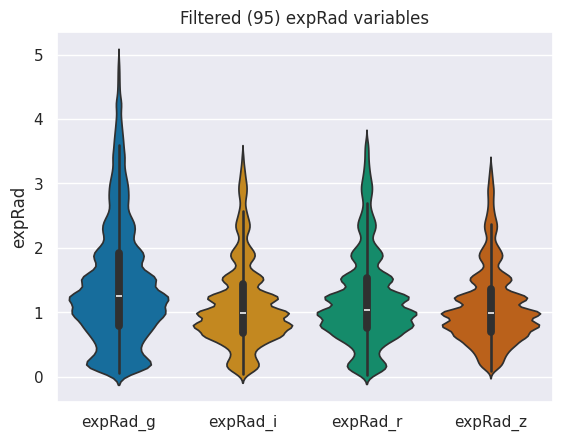

In [ ]:
### Filter outliers

th = 0.99
df_exp_filtered = df_expRad[(df_expRad < df_expRad.quantile(th)).all(axis=1) & (df_expRad > df_expRad.quantile(1-th)).all(axis=1)]
plt.title('Filtered (99) expRad variables');
plt.ylabel('expRad')
sns.violinplot(df_exp_filtered)

#plt.savefig('../IMG/filtered99_expRad_violin.png', dpi=300)

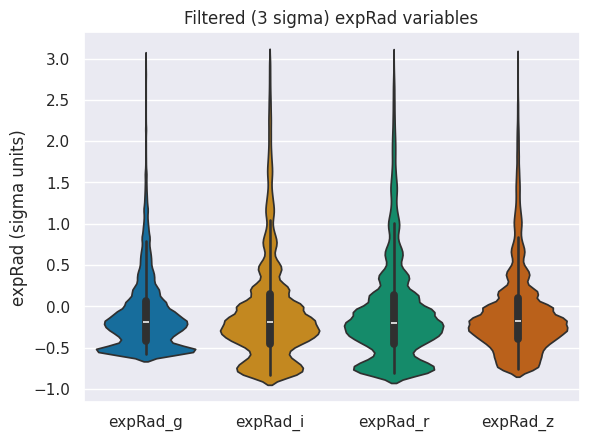

In [155]:
## Calculate distance in sigma units for all expRad variables
mean_exp = df_expRad.mean()
std_exp = df_expRad.std()

df_exp_sigma = (df_expRad - mean_exp)/std_exp

# Filter the outliers considering 3 sigma
th_sigma = 3
df_exp_sigma_filtered = df_exp_sigma[(df_exp_sigma < th_sigma).all(axis=1) & (df_exp_sigma > -th_sigma).all(axis=1)]
plt.title('Filtered (3 sigma) expRad variables');
plt.ylabel('expRad (sigma units)');
sns.violinplot(df_exp_sigma_filtered)

plt.savefig('../IMG/expRad_filtered3sigma_violin.png', dpi=300)

In [156]:
## Calculate moments for raw, filter95, filter99 and 3sigma

df_exp_filtered_95 = df_expRad[(df_expRad < df_expRad.quantile(.95)).all(axis=1) & (df_expRad > df_expRad.quantile(1-.95)).all(axis=1)]

moments_exp_raw = pd.DataFrame({'Mean': df_expRad.mean(), 'Variance': df_expRad.var(), 'Skewness': df_expRad.skew(), 'Kurtosis': df_expRad.kurtosis()})
moments_exp_95 = pd.DataFrame({'Mean': df_exp_filtered_95.mean(), 'Variance': df_exp_filtered_95.var(), 'Skewness': df_exp_filtered_95.skew(), 'Kurtosis': df_exp_filtered_95.kurtosis()})
moments_exp_99 = pd.DataFrame({'Mean': df_exp_filtered.mean(), 'Variance': df_exp_filtered.var(), 'Skewness': df_exp_filtered.skew(), 'Kurtosis': df_exp_filtered.kurtosis()})
moments_exp_3sigma = pd.DataFrame({'Mean': df_exp_sigma_filtered.mean(), 'Variance': df_exp_sigma_filtered.var(), 'Skewness': df_exp_sigma_filtered.skew(), 'Kurtosis': df_exp_sigma_filtered.kurtosis()})  

moments_exp_raw,moments_exp_95, moments_exp_99,moments_exp_3sigma

(              Mean  Variance   Skewness    Kurtosis
 expRad_g  1.753804  9.083355  10.559036  163.455887
 expRad_i  1.219606  2.152621  11.642633  340.121652
 expRad_r  1.319463  2.641787  11.843468  321.473479
 expRad_z  1.246792  2.737114  15.262944  430.719501,
               Mean  Variance  Skewness  Kurtosis
 expRad_g  1.439905  0.880220  0.937941  0.653896
 expRad_i  1.120543  0.436940  1.078601  1.069169
 expRad_r  1.208978  0.520419  0.972723  0.824092
 expRad_z  1.104123  0.363778  1.079458  1.086566,
               Mean  Variance  Skewness  Kurtosis
 expRad_g  1.539219  1.927811  1.822742  4.683310
 expRad_i  1.170873  0.934722  1.849550  4.329101
 expRad_r  1.260615  1.080049  1.708829  3.696518
 expRad_z  1.168790  0.804147  1.850648  4.424852,
               Mean  Variance  Skewness  Kurtosis
 expRad_g -0.092781  0.206442  1.837084  4.977971
 expRad_i -0.068115  0.409597  1.719846  3.701213
 expRad_r -0.069909  0.388706  1.597030  3.180679
 expRad_z -0.073358  0.280787  1

In [157]:
# Add a new column with the filter type and export all these dataframes to single a csv file

moments_exp_raw['Filter'] = 'Raw'
moments_exp_95['Filter'] = 'P95'
moments_exp_99['Filter'] = 'P99'
moments_exp_3sigma['Filter'] = 'ThreeSigma'

all_moments = [moments_exp_raw,moments_exp_95, moments_exp_99,moments_exp_3sigma]
final_results_df = pd.concat(all_moments)

final_results_df.to_csv('expRad_moments_filters.csv', index=True)

### extinction

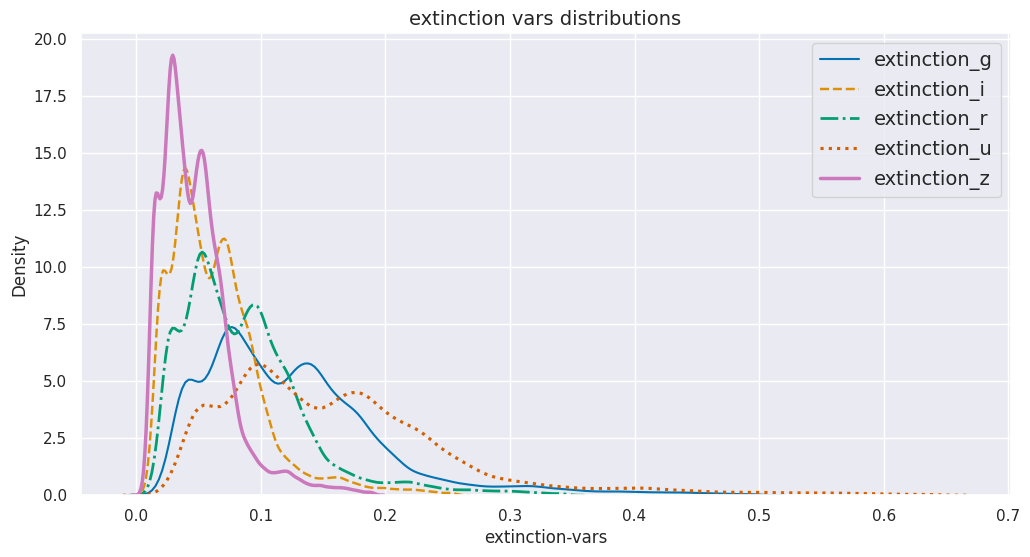

In [228]:
vars = ['extinction_g', 'extinction_i', 'extinction_r',
       'extinction_u', 'extinction_z']
styles = ['-', '--', '-.', ':', '-']
lws = np.linspace(1.5, 2.5, 5)

plt.figure(figsize=(12,6)); fs=14
plt.title('extinction vars distributions', fontsize=fs)

for var, style, lw in zip(vars, styles, lws):
    sns.kdeplot(data=df_7, x=var, label=var, linestyle=style, linewidth=lw)

plt.xlabel('extinction-vars')
plt.legend(fontsize=fs)

#plt.savefig('../IMG/extinction_KDE.png', dpi=400)

# Visualizar matriz de correlación

- Esta información será muy relevante a la hora de seleccionar los features de la red neuronal

Text(0.5, 1.0, 'Correlation Heatmap')

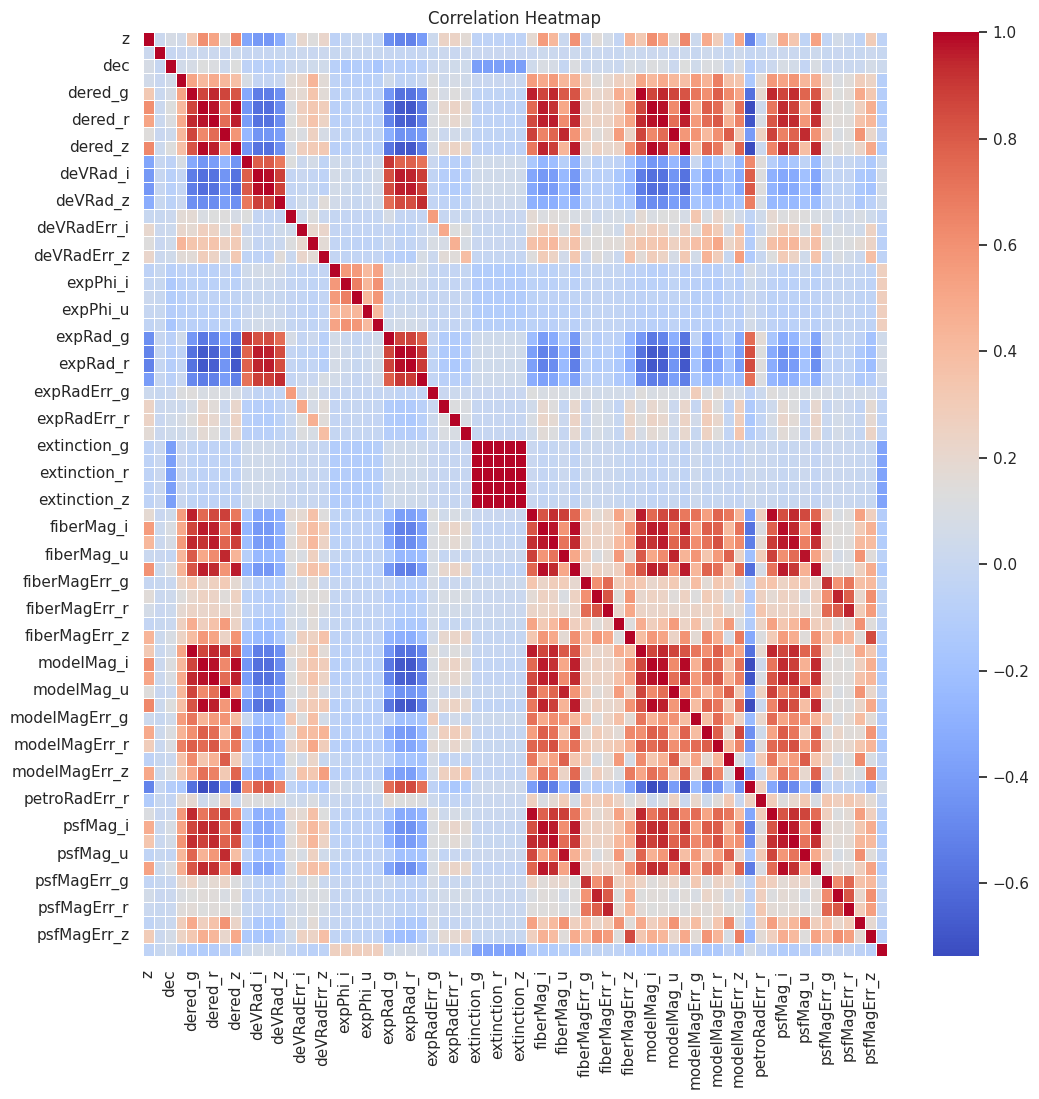

In [230]:
# calcular correlaciones
corr_matrix = df_7.corr()

plt.figure(figsize=(12, 12)) 
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')

- Se destaca la correlación practicamente unitaria entre las variables de extinción, que ya se anticipaba en el análisis previo 
- Además de las correlaciones que se generan entre las bandas de cada variable, se aprecia una zona de alta correlación en la región inferior derecha de la gráfica, donde se encuentran las variables `fiberMag`, `modelMag`, `psfMag` y sus errores.
- No se observa que ninguna de las varibles presente una alta correlación lineal con el redshift `z`

In [ ]:
# Definir un threshold para el filtro
threshold = 0.95

# 1. calcular el valor absoluto de la correlación
corr_abs = corr_matrix.abs()

# Dad la simetría, se analiza solo el triángulo superior
upper_triangle = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))         # k=1 para ignorar la diagonal
highly_correlated_pairs = upper_triangle.stack()[upper_triangle.stack() > threshold]

print("-- Pares de variables altamente correlacionadas (> 0.95) --")
print(highly_correlated_pairs.sort_values(ascending=False))

-- Pares de variables altamente correlacionadas (> 0.9) --
extinction_u   extinction_z    1.000000
extinction_i   extinction_z    1.000000
               extinction_u    1.000000
extinction_g   extinction_u    1.000000
               extinction_z    1.000000
               extinction_i    1.000000
               extinction_r    1.000000
extinction_i   extinction_r    1.000000
extinction_r   extinction_z    1.000000
               extinction_u    1.000000
dered_z        modelMag_z      0.999855
dered_i        modelMag_i      0.999734
dered_r        modelMag_r      0.999562
dered_g        modelMag_g      0.999268
dered_u        modelMag_u      0.999071
dered_i        dered_z         0.989915
modelMag_i     modelMag_z      0.989876
dered_i        modelMag_z      0.989773
dered_z        modelMag_i      0.989624
fiberMag_g     psfMag_g        0.988139
fiberMag_r     psfMag_r        0.986381
fiberMag_i     fiberMag_z      0.985880
               psfMag_i        0.982764
expRad_i       expRad

In [248]:
# Definir dataframe filtrando algunas de las variables altamente correlacionadas

to_drop = ['extinction_g','extinction_r','extinction_i','extinction_z',                # Variables a filtrar
           'modelMag_r', 'modelMag_i', 'modelMag_z',
           'fiberMagErr_r', 'fiberMagErr_i',
           'fiberMag_g', 'fiberMag_r', 'fiberMag_i', 'fiberMag_z',
           'expRad_r', 'expRad_i']        
                           
df_corr_95 = df_7.drop(to_drop,axis=1)

# Generar archivo de datos filtrados

- Exportar dataframes en formato csv
    - Se exportan distintos datasets para poner a prueba al modelo sobre variados
- En el notebook `model_launcher` se configuran los subgrupos de features a ser utilizados

In [ ]:
# Exportar dataframe con filtro sobre los valores -9999 y quitando la columna petroRadErr_r  
df_1.drop('petroRadErr_r',axis=1).to_csv('clean1_150k.csv', index=False)

# Exportar dataframe con filtro sobre los valores -1000 y -9999
df_2.to_csv('clean2_150k.csv', index=False)

# exportar último dataframe antes de filtrar por correlación
df_7.to_csv('clean7_150k.csv', index=False)

# Exportar dataframe filtrado por correlación < 0.95
df_corr_95.to_csv('clean7_corr09_150k.csv', index=False)

Text(0, 0.5, 'z')

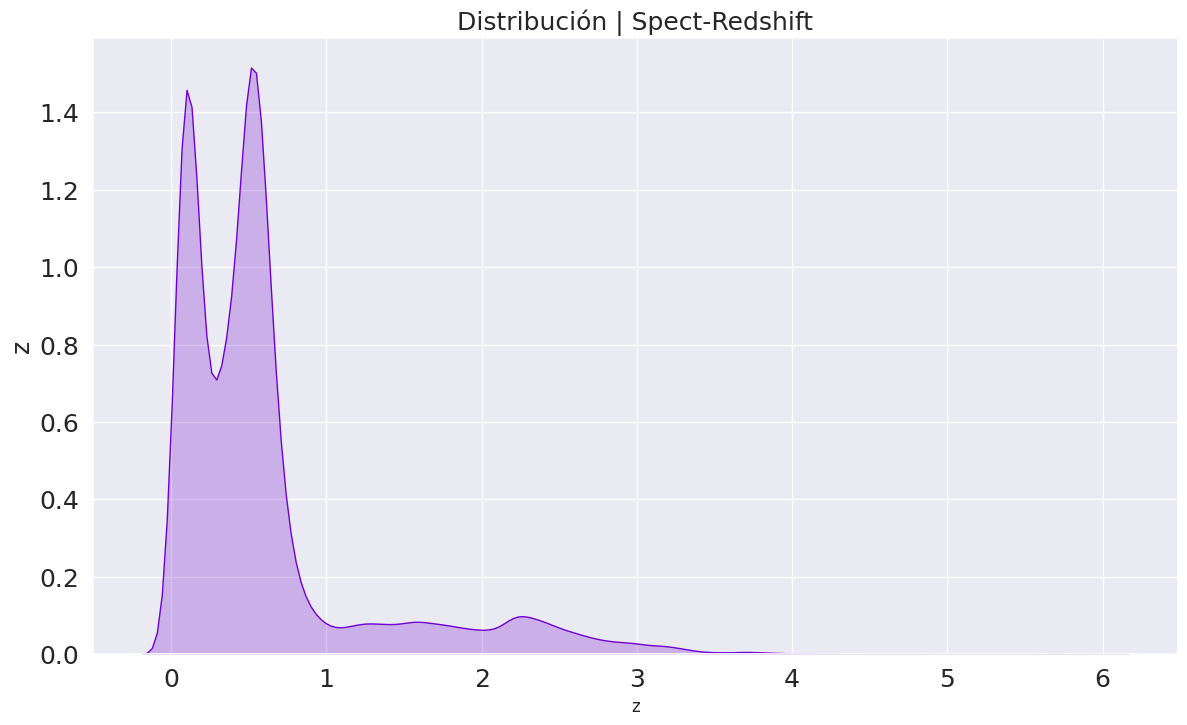

In [21]:
# Modifications-Post

fig, (ax_top) = plt.subplots(nrows=1, ncols=1,figsize=(14, 8))

dff = pd.read_csv('clean1_150k.csv')

sns.kdeplot(dff['z'], fill=True, color="#7000D2")

#ax_top.grid(True)
ax_top.set_title('Distribución | Spect-Redshift', fontsize=18)
ax_top.tick_params(labelsize=18)
#ax_top.legend(frameon=True, shadow=True, fontsize=15, facecolor='#E9FF36', edgecolor='k', loc='upper left')
ax_top.set_ylabel('z', fontsize=18)
#ax_top.set_xlabel('Día relativo al evento', fontsize=16)
#plt.savefig('modelMagErr_boxplot_filtered.png', dpi=300)